# GraphRAG-NK — RQ1–RQ6 Analysis (02b, 12 curated MSR corpora)

*Port of `02_rq_analysis.ipynb` (v0.2) onto the v0.8 multi-platform ontology and
the 12 curated, peer-reviewed MSR datasets (`FRAMEWORK_DESIGN.md` §12 /
`REFINED_RQS_v0.3.md` §2). It asks the SAME questions as the v0.2 notebook —
the lexical, morpho-syntactic, rhetorical and marker–classifier frequency stats
the user still wants for tinkering — but every Cypher query now routes through
the `:Artefact` base label (`corpus_id` / `platform_id` / `venue_id`) and is
restricted to the curated corpora. The canonical v0.3 analysis lives in
`03_rq_analysis.ipynb`; this file is the schema-updated companion for the v0.2
question set.*

*Updated for the v0.3.1 restructure (2026-09-19): RQ1/RQ2/RQ3 here are
**Baseline 2a–c** — the descriptive linguistic anatomy of non-knowledge — in
`REFINED_RQS_v0.3.md` §3. Binding constraint: every rate is reported **per
genre**, token-normalised, never as a flat corpus mean.*

**Four layers of claim** (as in v0.2):
- **Layer 0 — instrument-level (RQ4a).** Taxonomy discriminability from the codebook, no corpus.
- **Layer 1 — descriptive (RQ1–RQ3).** What markers occur.
- **Layer 2 — comparative (RQ6).** How corpora, platforms and genres differ.
- **Layer 3 — critical (RQ4b–d, RQ5).** Where the theory and the method fail.

**Design invariants (unchanged):** signals are never collapsed; headline counts
use `status='active'` with `candidate` reported separately; non-NK contrastive
signals (boosters, `-free` privative) are excluded from every NK-positive
definition; the corpus registry excludes old-scope GitHub/Gmane nodes; every
marker weight is analysis-time metadata, never an ingest filter.

**Prerequisites:** populated Neo4j with the curated corpora ingested
(`--enrich` for RQ6 `REPLIES_TO`), the four codebook documents in `ontology/`,
the external drive mounted for RQ6.5's OpenMent roles, and
`pip install neo4j pandas numpy matplotlib scipy scikit-learn pyyaml`
(optional: `python-igraph leidenalg` for the RQ4 marker-community fallback).


In [34]:
# ── Configuration & connections ──────────────────────────────────────────────
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display
from neo4j import GraphDatabase

import sys
sys.path.insert(0, str(Path.cwd().parent))   # repo root, for settings
from settings import settings

driver = GraphDatabase.driver(
    settings.neo4j_uri, auth=(settings.neo4j_user, settings.neo4j_password)
)

# ── The sandbox guard, explained ─────────────────────────────────────────────
# learn/00_seed_sandbox.cypher tags every node it creates with `sandbox: true`,
# and its toy sentences carry real NK markers. If that seed was installed into
# THIS database, those signals would silently pollute every count. The
# production pipeline never writes `sandbox`, so the property exists only if you
# seeded. Referencing an unregistered property key makes Neo4j 5.x emit 01N52
# noise on every query, so the guard is resolved once here.
with driver.session() as _s:
    _prop_keys = {r[0] for r in _s.run("CALL db.propertyKeys()")}
SANDBOX_KEY_EXISTS = "sandbox" in _prop_keys


def q(cypher: str, **params) -> pd.DataFrame:
    """Run a Cypher query, return a DataFrame. All analysis goes through here.

    Columns are taken from the result keys, so an EMPTY result still yields a
    DataFrame with the right column names instead of a zero-column frame that
    crashes `.map(...)` downstream. This matters when a corpus (or the whole
    curated graph) has not been ingested yet.

    Queries write `@sandbox(u)` where they need the sandbox-exclusion guard; it
    expands to `coalesce(u.sandbox, false) = false` when sandbox data is
    present, or to `true` (a no-op the planner drops) when it isn't.
    """
    cypher = re.sub(
        r"@sandbox\((\w+)\)",
        lambda m: (f"coalesce({m.group(1)}.sandbox, false) = false"
                   if SANDBOX_KEY_EXISTS else "true"),
        cypher,
    )
    with driver.session() as session:
        result = session.run(cypher, **params)
        keys = result.keys()
        rows = [r.data() for r in result]
    return pd.DataFrame(rows, columns=keys)


# ── Interval helpers (v0.2, unchanged) ───────────────────────────────────────
# Used wherever the paper reports a proportion from a hand-coded sample. At
# n ≈ 400 the normal approximation misbehaves near 0 and 1 — which is exactly
# where the interesting cells are — so Wilson is the default, and zero counts
# get the rule of three instead of "0%".
def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float, float]:
    """Wilson score interval for k successes in n trials. Returns (p, lo, hi)."""
    if n == 0:
        return (float("nan"),) * 3
    p = k / n
    d = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return p, max(0.0, centre - half), min(1.0, centre + half)


def rule_of_three(n: int) -> float:
    """Upper 95% bound on a rate when 0 events were observed in n trials."""
    return 3.0 / n if n else float("nan")


def fmt_prop(k: int, n: int) -> str:
    """Report a proportion the way the paper should: never a bare '0%'."""
    if n == 0:
        return "n/a (empty denominator)"
    if k == 0:
        return f"0/{n} (95% upper bound ≤{rule_of_three(n):.2%})"
    p, lo, hi = wilson(k, n)
    return f"{k}/{n} = {p:.1%} [{lo:.1%}, {hi:.1%}]"


pd.set_option("display.max_rows", 200)
plt.rcParams["figure.figsize"] = (10, 5)
print("Connected to", settings.neo4j_uri)
print(f"sandbox key present in DB: {SANDBOX_KEY_EXISTS} → guard "
      f"{'ACTIVE (course data may be present — it will be excluded)' if SANDBOX_KEY_EXISTS else 'inert (no sandbox data; predicate omitted)'}")


Connected to bolt://localhost:7687
sandbox key present in DB: False → guard inert (no sandbox data; predicate omitted)


In [35]:
# ── Rule metadata, loaded from the SAME YAML files the annotators load ───────
ROOT = Path.cwd().parent
V = settings.pattern_set_version

morpho_yaml = yaml.safe_load((ROOT / "patterns" / f"morpho_syntactic_v{V}.yml").read_text())
lex_yaml    = yaml.safe_load((ROOT / "lexicons" / f"en_core_v{V}.yml").read_text())
rhet_yaml   = yaml.safe_load((ROOT / "patterns" / f"rhetorical_v{V}.yml").read_text())
wf_yaml     = yaml.safe_load((ROOT / "patterns" / f"word_formation_v{V}.yml").read_text())

# RQ2: scoped (DependencyMatcher) vs cue-only (Matcher) morpho rules.
SCOPED_RULES = [p["id"] for p in morpho_yaml["patterns"] if p.get("type") == "DependencyMatcher"]

# ── Authoritative rule-id sets, rebuilt from the YAMLs (2026-09-21 revision) ──
# The graph stores each Signal with the status its rule had AT ANNOTATION TIME.
# The 2026-09-21 marker revision removed 45 rules (all boosters, every M-5
# SE-native lexical marker, bare negation, the bare question mark, and three
# rhetorical figures) and promoted 6 others, so `s.status` in the graph can no
# longer be trusted as analysis truth: retired-active rules still carry
# status='active' there and promoted rules still carry 'candidate'. Resolution
# is analysis-side (no graph rewrite): filter on rule_id membership, never on
# s.status. A signal whose rule_id is absent from the current YAMLs is ghost
# data from a retired rule and must not be counted.
def _split_rules_by_status():
    # lexical.py emits rule_id as f"lex.{entry.id}" — the lexicon YAML stores the
    # bare id ("uncertain"), so the prefix must be re-applied here or the
    # rule_id IN $active_rules filter drops EVERY lexical signal (mismatch bug).
    active, candidate = set(), set()
    for e in lex_yaml.get("entries", []):
        rid = f"lex.{e['id']}" if not e["id"].startswith("lex.") else e["id"]
        (active if e.get("status") == "active" else candidate).add(rid)
    for p in morpho_yaml.get("patterns", []):
        (active if p.get("status") == "active" else candidate).add(p["id"])
    for f in rhet_yaml.get("figures", []):
        (active if f.get("status") == "active" else candidate).add(f["rule_id"])
    for a in wf_yaml.get("prefixes", []) + wf_yaml.get("suffixes", []):
        (active if a.get("status") == "active" else candidate).add(a["rule_id"])
    # Return LISTS (sorted): the Bolt driver rejects Python set parameters.
    return sorted(active), sorted(candidate)

ACTIVE_RULE_IDS, CANDIDATE_RULE_IDS = _split_rules_by_status()
VALID_RULE_IDS = sorted(set(ACTIVE_RULE_IDS) | set(CANDIDATE_RULE_IDS))
RULE_STATUS = {rid: "active" for rid in ACTIVE_RULE_IDS}
RULE_STATUS.update({rid: "candidate" for rid in CANDIDATE_RULE_IDS})

# Non-NK contrastive subcategories — NEVER counted as NK evidence.
# 'booster' and the -free privative are PINNED here: the v0.2.1 lexicon revision
# removed the booster entries from en_core_v0.2.yml, so deriving this set from
# polarity alone would silently re-admit the booster signals the graph still
# holds (the RQ1.3 figure bug that motivated this cell's rewrite).
NON_NK_SUBCATS = sorted(
    {"booster", "privative", "privative_certainty"} |
    {e.get("subcategory") for e in lex_yaml.get("entries", []) if e.get("polarity") == "certainty"} |
    {s.get("subcategory") for s in wf_yaml.get("suffixes", []) if s.get("polarity") == "certainty"}
)

# RQ2a/1: SE-native lexical subcategories (absent from the source taxonomies).
# The M-5 lexical markers were retired in the v0.2.1 revision, so the lexical
# SE-native share is 0 by construction; kept for the disclosure tables.
SE_NATIVE_LEX = ["repro_gap", "opacity", "spec_gap", "doc_gap",
                 "code_comment_marker", "non_deterministic_behaviour"]

# RQ2c/3: SE-native vs canonical rhetorical subtypes. ('obscurity' lost its
# only rule — rhetor.metaphor.obscurity.fog — in the same revision.)
SE_NATIVE_RHET = ["opacity", "hidden_extent", "obscurity"]

# ── THE marker-positive definition, defined ONCE ─────────────────────────────
# RQ4's sampling frame and RQ5's 2×2 must partition the SAME population, or the
# two analyses silently describe different corpora. Every query below that needs
# "is this signal NK evidence?" interpolates this predicate rather than
# restating it. `s` is the Signal variable; `$non_nk`, `$rule_version` and
# `$active_rules` are supplied as parameters by the caller. "Active" is resolved
# via rule_id membership (current YAML truth), NOT via s.status (stale graph
# value from annotation time).
NK_SIGNAL_PREDICATE = """
    s.layer <> 'classifier'
    AND s.status IN ['active', 'candidate']
    AND s.rule_id IN $active_rules
    AND s.rule_version = $rule_version
    AND NOT coalesce(s.subcategory, '') IN $non_nk
    AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.uncharted' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'terra')
"""

print(f"pattern_set_version = {V}")
print(f"Scoped rules ({len(SCOPED_RULES)}):", SCOPED_RULES)
print(f"Active rules: {len(ACTIVE_RULE_IDS)}, candidate: {len(CANDIDATE_RULE_IDS)}, "
      f"total valid: {len(VALID_RULE_IDS)}")
print("Non-NK subcats:", NON_NK_SUBCATS)
print("\nNK signal predicate (shared by RQ4 + RQ5):", NK_SIGNAL_PREDICATE)


pattern_set_version = 0.2
Scoped rules (7): ['morph.epi.neg_cognition', 'morph.epi.neg_cognition_modal', 'morph.epi.neg_cognition_ascribed', 'morph.hedge.shield_think', 'morph.neg.scoped_epistemic', 'morph.tense.past_nk_notyet', 'morph.syn.embedded_question']
Active rules: 48, candidate: 18, total valid: 66
Non-NK subcats: ['booster', 'privative', 'privative_certainty']

NK signal predicate (shared by RQ4 + RQ5): 
    s.layer <> 'classifier'
    AND s.status IN ['active', 'candidate']
    AND s.rule_id IN $active_rules
    AND s.rule_version = $rule_version
    AND NOT coalesce(s.subcategory, '') IN $non_nk
    AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.u

In [36]:
# ── The ignorance codebook, loaded from the pre-registered YAML ─────────────
# Same single-source-of-truth discipline as the pattern files above: the codebook
# is the instrument, and this notebook must never contain a hand-typed category
# list that can drift from it. Everything RQ4a reports is derived here.
CODEBOOK_PATH = ROOT / "ontology" / "ignorance_codebook_v0.1.yml"
codebook = yaml.safe_load(CODEBOOK_PATH.read_text())

_cat_rows, _dim_rows, _rel_rows = [], [], []
for tax in codebook["taxonomies"]:
    tid = tax["taxonomy_id"]
    access = ("full_primary" if tax.get("full_text_accessed") else "partial_or_secondary")
    for c in tax.get("categories", []):
        _cat_rows.append({
            "taxonomy": tid, "type_id": c["type_id"], "name": c["name"],
            "parent": c.get("parent"),
            "confidence": c.get("definition_confidence"),
            "access": access,
            "has_vagueness": bool(c.get("source_vagueness")),
        })
        for nb in c.get("near_neighbours", []) or []:
            test = (nb.get("distinguishing_test") or "")
            _rel_rows.append({
                "from": c["type_id"], "to": nb["type_id"],
                "from_tax": c["type_id"].split(".")[0],
                "to_tax": nb["type_id"].split(".")[0],
                "relation": nb.get("relation"),
                "none_possible": test.strip().upper().startswith("NONE_POSSIBLE"),
            })
    for d in tax.get("dimensions", []):
        _dim_rows.append({
            "taxonomy": tid, "dimension_id": d["dimension_id"], "name": d["name"],
            "permitted_values": [v.get("value") if isinstance(v, dict) else v
                                 for v in d.get("permitted_values", [])],
            "confidence": d.get("definition_confidence"), "access": access,
        })

CATS = pd.DataFrame(_cat_rows)
DIMS = pd.DataFrame(_dim_rows)
RELS = pd.DataFrame(_rel_rows)

CATEGORY_IDS = set(CATS["type_id"])
DIMENSION_IDS = set(DIMS["dimension_id"])
DIMENSION_VALUES = {r.dimension_id: set(r.permitted_values) for r in DIMS.itertuples()}

# Non-fit codes live in CODING_MANUAL.md, not the codebook YAML (they are not
# imported categories). They are enumerated here because every validation step
# below needs them, and because keeping them apart is what stops the RESIDUAL
# rate from absorbing marker false positives.
NON_FIT_CODES = {"RESIDUAL", "NOT_NK", "UNCODABLE"}
VALID_PRIMARY_CODES = CATEGORY_IDS | NON_FIT_CODES

# Catch-all codes: broad, low-confidence categories sitting immediately before
# STEP 5 in the decision tree. A unit landing here would otherwise have been
# RESIDUAL, so RQ4d reports the residual rate both with and without them.
CATCH_ALL_CODES = {"gross.ignorance", "smithson.error", "smithson.irrelevance"}

# Smithson is hierarchical: coverage must be computed hierarchy-aware, or the
# branch-level categories look empty merely because coders reached a leaf.
PARENT_OF = {r.type_id: r.parent for r in CATS.itertuples()
             if isinstance(r.parent, str) and r.parent}


def ancestors_of(type_id: str) -> list[str]:
    """All ancestor category ids of `type_id` (excluding itself)."""
    out, cur = [], PARENT_OF.get(type_id)
    while cur:
        out.append(cur)
        cur = PARENT_OF.get(cur)
    return out


print(f"Codebook v{codebook['version']} loaded from {CODEBOOK_PATH.name}")
print(f"  {len(CATS)} categories across {CATS.taxonomy.nunique()} categorical taxonomies")
print(f"  {len(DIMS)} Wehling dimensions ({sum(len(v) for v in DIMENSION_VALUES.values())} permitted values)")
print(f"  {len(RELS)} near-neighbour relations recorded")
print(f"  hierarchy: {len(PARENT_OF)} categories have a parent (all Smithson)")
print(f"  catch-all codes tracked for RQ4d reversal: {sorted(CATCH_ALL_CODES)}")


Codebook v0.1 loaded from ignorance_codebook_v0.1.yml
  28 categories across 3 categorical taxonomies
  3 Wehling dimensions (9 permitted values)
  31 near-neighbour relations recorded
  hierarchy: 12 categories have a parent (all Smithson)
  catch-all codes tracked for RQ4d reversal: ['gross.ignorance', 'smithson.error', 'smithson.irrelevance']


---
## §2.0 The curated corpus registry (scope enforcement)

Every 02b query attributes a TextUnit to a corpus, platform and genre **through
its parent artefact's `corpus_id`** (`MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)`).
The registry below is the single place that maps `corpus_id` → (genre, platform,
label). Anything not in the registry (old GitHub/Gmane data, `ocean`) is
**excluded from every analysis**. This cell also reports which corpora are
actually present, so a missing corpus is visible instead of silently becoming an
empty cell.

`corpus_id` values are those the v0.8 ingesters write into `Artefact.source_corpus` /
`corpus_id` (`FRAMEWORK_DESIGN.md` §12). Genres are the v0.3 communicative
genres (`REFINED_RQS_v0.3.md` §2).

In [48]:
# ── The corpus → genre/platform registry ────────────────────────────────────
# corpus_id            : (genre, platform, label)
CORPUS_REGISTRY = {
    "apache-jira":             ("tracker", "jira", "Apache Jira (MSR'23)"),
    "alternative-jira":        ("tracker", "jira", "Alternative Jira (MSR'22)"),
    #"bugsrepo":                ("tracker", "bugzilla", "BugsRepo"),
    "numfocus":                ("tracker", "github-shaped", "NumFOCUS activity"),
    "curated-email-code-reviews": ("email", "email", "Curated email code reviews (Liang 2024)"),
    "kummerfeld-irc":          ("chat", "irc", "Kummerfeld Ubuntu IRC"),
    "preethac-slack":          ("chat", "slack", "preethac Slack (disentangled)"),
    "disco":                   ("chat", "discord", "DISCO-A Discord"),
    "gittercom":               ("chat", "gitter", "GitterCom"),
    "livechat-gitter":         ("chat", "gitter", "LiveChatGitter"),
    #"so-emotion-gold":         ("qa", "stackoverflow", "SO emotion gold (Novielli 2018)"),
    "sotorrent":               ("qa", "stackoverflow", "SOTorrent (Baltes 2018)"),
    "openment":                ("tracker", "gso", "OpenMent GSoC"),
}
IN_SCOPE_CORPORA = sorted(CORPUS_REGISTRY)


def genre_of(corpus_id: str) -> str:
    return CORPUS_REGISTRY.get(corpus_id, ("EXCLUDED", "?", "?"))[0]


def platform_of(corpus_id: str) -> str:
    return CORPUS_REGISTRY.get(corpus_id, ("EXCLUDED", "?", "?"))[1]

GENRES = ["tracker", "email", "chat", "qa"]

# ── 2. Unified Design System & Palette Mapping ───────────────────────────────
INK = "#0F172A"         # Near-black slate (primary text)
GREY_TEXT = "#475569"   # Secondary text / annotations
LINE = "#E2E8F0"        # Gridline color
BORDER_DARK = "#0F172A"

FIG_DIR = ROOT / "notebooks" / "figs"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def _export_fig(fig: plt.Figure, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=300)

# ── Presence check + denominators: what is actually in the database ──────────
den = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
WHERE @sandbox(u)
RETURN coalesce(p.corpus_id, '') AS corpus,
       coalesce(p.platform_id, '') AS platform_id,
       count(DISTINCT p) AS artefacts,
       count(DISTINCT u) AS units,
       sum(coalesce(u.token_count, 0)) AS tokens
""")
if not len(den):
    den = pd.DataFrame(columns=["corpus", "platform_id", "artefacts", "units", "tokens"])
den["genre"] = den.corpus.map(genre_of)

census = den[den.genre != "EXCLUDED"].copy()
excluded = den[den.genre == "EXCLUDED"]
print("In-scope corpora present in the graph:")
display(census.assign(mean_tokens_per_unit=lambda d: (d.tokens / d.units.replace(0, np.nan)).round(1))
              .sort_values("units", ascending=False))
if len(excluded):
    print("\n⚠️ Old-scope / unregistered corpora found (EXCLUDED from all 02b analyses):")
    display(excluded)
print(f"\nTotal in-scope: {int(census.units.sum()):,} TextUnits from {int(census.artefacts.sum()):,} artefacts,"
      f"{int(census.tokens.sum()):,} tokens, {len(census)} corpora")

# Corpus-id / genre → tokens & units, needed by every per-corpus and per-genre rate.
CORPUS_TOKENS = dict(zip(census.corpus, census.tokens.astype(int)))
CORPUS_UNITS   = dict(zip(census.corpus, census.units.astype(int)))
GENRE_TOKENS   = census.groupby("genre").tokens.sum().astype(int).to_dict()
GENRE_UNITS    = census.groupby("genre").units.sum().astype(int).to_dict()
TOTAL_TOKENS   = int(census.tokens.sum())
TOTAL_UNITS    = int(census.units.sum())


In-scope corpora present in the graph:


,corpus,platform_id,artefacts,units,tokens,genre,mean_tokens_per_unit
6,curated-email-code-reviews,mailing_list,10087419,14561855,543359540,email,37.3
3,alternative-jira,jira,2686220,14006542,787303749,tracker,56.2
2,gittercom,gitter,2950192,2950192,38080515,chat,12.9
1,apache-jira,jira,1157539,2207299,113823637,tracker,51.6
4,livechat-gitter,gitter,1649133,1649133,19614925,chat,11.9
10,sotorrent,stackoverflow,1215994,1613250,95781465,qa,59.4
0,disco,discord,1427726,1427726,11670353,chat,8.2
5,openment,openment,75284,1335605,36865064,tracker,27.6
7,numfocus,numfocus,332983,332983,2169654,tracker,6.5
9,preethac-slack,slack,209769,209769,3230218,chat,15.4



⚠️ Old-scope / unregistered corpora found (EXCLUDED from all 02b analyses):


,corpus,platform_id,artefacts,units,tokens,genre
11,,,4,8,230,EXCLUDED



Total in-scope: 40,333,764 TextUnits from 21,831,669 artefacts,1,652,321,337 tokens, 11 corpora


In [ ]:
census

,corpus,platform_id,artefacts,units,tokens,genre
0,disco,discord,1427726,1427726,11670353,chat
1,apache-jira,jira,1157539,2207299,113823637,tracker
2,gittercom,gitter,2950192,2950192,38080515,chat
3,alternative-jira,jira,2686220,14006542,787303749,tracker
4,livechat-gitter,gitter,1649133,1649133,19614925,chat
5,openment,openment,75284,1335605,36865064,mentor_mentee
6,curated-email-code-reviews,mailing_list,10087419,14561855,543359540,review_email
7,numfocus,numfocus,332983,332983,2169654,tracker
8,kummerfeld-irc,irc,39410,39410,422217,chat
9,preethac-slack,slack,209769,209769,3230218,chat


---
## 0 · Corpus overview & sanity checks
Before any RQ: confirm the graph looks like a corpus worth analysing. A silent annotator
layer, missing verdicts, leftover `quotation` units, or an unpopulated `token_count` would
corrupt every downstream number — cheaper to fail loudly here.

**v0.2 change kept:** §0.5 checks `token_count`, because every rate in RQ1/RQ3/RQ6 is now
token-normalised and a null-heavy `token_count` would silently produce nonsense rates rather
than an error.

In [ ]:
# §0.1 — Node counts per label (sandbox excluded)
df_nodes = q("""
MATCH (n) WHERE @sandbox(n)
RETURN labels(n)[0] AS label, count(*) AS n ORDER BY n DESC
""")
if not len(df_nodes):
    df_nodes = pd.DataFrame(columns=["label", "n"])
df_nodes.style.background_gradient(subset=['n'], cmap='Blues')


,label,n
0,Signal,144344356
1,TextUnit,40333772
2,ClassifierVerdict,39218345
3,Artefact,11486107
4,EmailMessage,10087431
5,Actor,1338456
6,StackOverflowPost,661327
7,Issue,210056
8,PullRequest,198293
9,Conversation,7247


In [5]:
# §0.2 — Signals per layer × status, restricted to in-scope units.
# Every rule layer must be non-zero; the candidate column shows how much evidence
# is excluded from headline numbers.
df = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
  AND s.rule_id IN $valid_rules
  AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.uncharted' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'terra')
RETURN s.layer AS layer, s.rule_id AS rule_id, count(*) AS n
""", corpora=IN_SCOPE_CORPORA, valid_rules=VALID_RULE_IDS)
df["status"] = df.rule_id.map(RULE_STATUS)
layer_status = df.pivot_table(index="layer", columns="status", values="n",
                             aggfunc="sum", fill_value=0)
silent = {"lexical", "morpho_syntactic", "word_formation", "rhetorical"} - set(layer_status.index)
if silent:
    print(f"⚠️ SILENT LAYERS (no signals at all): {silent} — check annotator startup logs!")
layer_status


status,active,candidate
layer,,
lexical,391345,1382778
morpho_syntactic,11164792,26505441
rhetorical,582894,10796
word_formation,0,9943901


In [ ]:
# §0.3 — Rule-version mix.
# The classifier layer is excluded: its rule_version carries the MODEL string, so
# it would always report ">1 version" and cry wolf. The real pattern-set mix is
# checked on its own.
df = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora AND s.layer <> 'classifier'
RETURN s.rule_version AS rule_version, count(*) AS n ORDER BY n DESC
""", corpora=IN_SCOPE_CORPORA)
if len(df) > 1:
    print("⚠️ MULTIPLE pattern-set versions among RULE signals (ablation run?).")
    print("   Every query below filters on $rule_version, so headline numbers are safe,")
    print("   but check that the version you analyse is the one you meant.")
print(f"Analysing rule_version = {V!r}")
display(df)

# Classifier versions reported separately — informational, never a warning.
q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:HAS_SIGNAL]->(s:Signal {layer: 'classifier'})
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
RETURN s.rule_version AS classifier_version, count(*) AS n ORDER BY n DESC
""", corpora=IN_SCOPE_CORPORA)


Analysing rule_version = '0.2'


,rule_version,n
0,0.2,105125967


,classifier_version,n
0,roberta-non-knowledge-v8-base,39218337


In [ ]:
# §0.4 — RQ6 methodological control: quotation segments must not exist as
# TextUnits (excluded at extraction so quoted text cannot double-count a prior
# author's NK).
df = q("MATCH (u:TextUnit {role: 'quotation'}) RETURN count(u) AS n")
n_quotes = int(df.iloc[0, 0]) if len(df) else 0
assert n_quotes == 0, "quotation TextUnits found — RQ6 exclusion control violated!"
print("OK: no quotation TextUnits (RQ6 control holds).")

# Genre summary of the denominators computed in §2.0.
den_summ = pd.DataFrame({
    "genre": GENRES,
    "units": [GENRE_UNITS.get(g, 0) for g in GENRES],
    "tokens": [GENRE_TOKENS.get(g, 0) for g in GENRES],
}).assign(mean_tokens_per_unit=lambda d: (d.tokens / d.units.replace(0, np.nan)).round(1))
print(f"TextUnits: {TOTAL_UNITS:,}  |  tokens: {TOTAL_TOKENS:,}")
display(den_summ)


OK: no quotation TextUnits (RQ6 control holds).


NameError: name 'GENRE_UNITS' is not defined

In [ ]:
# §0.5 — Unit-length diagnostic. THE control that decides whether cross-genre
# findings are real or an artefact of unit size.
#
# v0.1 reported every rate per 1k UNITS; if units differ systematically in length
# across corpora/genres, a per-unit rate is inflated for the longer units by
# exactly the length ratio. Everything below is therefore reported per 1k TOKENS,
# and this cell quantifies how much that matters on the curated corpus.
null_tok = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora AND u.token_count IS NULL
RETURN count(*) AS n
""", corpora=IN_SCOPE_CORPORA).iloc[0, 0]
if null_tok:
    print(f"⚠️ {null_tok:,} TextUnits have NULL token_count — token-normalised rates "
          f"below are computed over the remainder and will UNDERSTATE denominators.")
else:
    print("OK: token_count populated on every in-scope TextUnit.")

lens = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora AND u.token_count IS NOT NULL
RETURN coalesce(p.corpus_id, '') AS corpus,
       count(*) AS units,
       round(avg(u.token_count), 1) AS mean_tokens,
       percentileCont(u.token_count, 0.5) AS median_tokens,
       percentileCont(u.token_count, 0.9) AS p90_tokens
ORDER BY units DESC
""", corpora=IN_SCOPE_CORPORA)
lens["genre"] = lens.corpus.map(genre_of)
display(lens)

if len(lens):
    ratio = lens.mean_tokens.max() / lens.mean_tokens.min()
    print(f"\nMean unit-length ratio across corpora: {ratio:.1f}× "
          f"({lens.loc[lens.mean_tokens.idxmax(), 'corpus']} longest vs "
          f"{lens.loc[lens.mean_tokens.idxmin(), 'corpus']} shortest)")
    if ratio > 1.15:
        print("→ MATERIAL. Any per-UNIT rate comparison across corpora/genres is "
              "confounded by this ratio. All cross-corpus rates below use tokens "
              "as the denominator.")
    else:
        print("→ Small. Per-unit and per-token comparisons should agree; both are reported.")


OK: token_count populated on every in-scope TextUnit.


,corpus,units,mean_tokens,median_tokens,p90_tokens,genre
0,curated-email-code-reviews,14561855,37.3,11.0,81.0,review_email
1,alternative-jira,14006542,56.2,20.0,115.0,tracker
2,gittercom,2950192,12.9,9.0,27.0,chat
3,apache-jira,2207299,51.6,12.0,116.0,tracker
4,livechat-gitter,1649133,11.9,8.0,25.0,chat
5,sotorrent,1613250,59.4,38.0,139.0,qa
6,disco,1427726,8.2,6.0,17.0,chat
7,openment,1335605,27.6,14.0,62.0,mentor_mentee
8,numfocus,332983,6.5,6.0,11.0,tracker
9,preethac-slack,209769,15.4,11.0,33.0,chat



Mean unit-length ratio across corpora: 9.1× (sotorrent longest vs numfocus shortest)
→ MATERIAL. Any per-UNIT rate comparison across corpora/genres is confounded by this ratio. All cross-corpus rates below use tokens as the denominator.


In [6]:
# Baseline 2.0 — Single-pull NK signal table used by every rate in RQ1/RQ2/RQ3
# (mirrors 03_rq_analysis.ipynb §4.0). Signals are attributed to their TextUnit's
# parent corpus, then to a genre; anything outside the §2.0 registry is EXCLUDED.
# v0.3.1 binding constraint (REFINED_RQS_v0.3.md §3): every rate below is
# reported per genre, never as a flat corpus mean.
sig = q(f"""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
WHERE @sandbox(u) AND {NK_SIGNAL_PREDICATE}
RETURN coalesce(p.corpus_id, '') AS corpus, s.layer AS layer,
       s.category AS category, s.subcategory AS subcategory, s.rule_id AS rule_id,
       count(s) AS signals
""", non_nk=NON_NK_SUBCATS, rule_version=V, active_rules=ACTIVE_RULE_IDS)
sig["genre"] = sig.corpus.map(genre_of)
sig = sig[sig.genre != "EXCLUDED"].copy()
sig["se_native"] = sig.subcategory.isin(SE_NATIVE_LEX)

# Active+candidate frame for the status-sensitivity tables (RQ1.1, RQ1.2, RQ2.1,
# RQ3.2). Restricted to the three rule layers via an explicit layer IN list —
# deliberately NOT the `s.layer <> 'classifier'` formulation the 03 RQ2a cell
# used, which let morpho-syntactic signals inflate the candidate lexical
# denominator (03 bug, fixed in 03 RQ2a on 2026-09-21). Ghost signals from
# rules retired in the v0.2.1 marker revision are dropped at the Cypher level
# via $valid_rules; status is then remapped from rule_id (YAML truth).
cand = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
WHERE @sandbox(u) AND s.layer IN ['lexical', 'morpho_syntactic', 'rhetorical']
  AND s.rule_id IN $valid_rules AND s.rule_version = $rule_version
  AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.uncharted' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'terra')
  AND NOT coalesce(s.subcategory, '') IN $non_nk
RETURN coalesce(p.corpus_id, '') AS corpus, s.layer AS layer,
       s.category AS category, s.subcategory AS subcategory, s.rule_id AS rule_id,
       count(s) AS signals, count(DISTINCT u) AS units
""", non_nk=NON_NK_SUBCATS, rule_version=V, valid_rules=VALID_RULE_IDS)
# Graph status is annotation-time truth; remap to the CURRENT YAML status so
# promoted rules count as active and retired rules never reach this frame
# (they are already excluded by the $valid_rules filter above).
cand["status"] = cand["rule_id"].map(RULE_STATUS)
cand["genre"] = cand.corpus.map(genre_of)
cand = cand[cand.genre != "EXCLUDED"].copy()

# One guard flag honoured by every RQ1/RQ2/RQ3 cell below (cells share a namespace).
GRAPH_EMPTY = len(sig) == 0
if GRAPH_EMPTY:
    print("⚠️ No in-scope NK signals yet — RQ1/RQ2/RQ3 skip until the pipeline has run.")
else:
    print(f"In-scope NK signals: {int(sig.signals.sum()):,} across {sig.genre.nunique()} genres")
    display(sig.groupby("genre").signals.sum().to_frame("signals"))

In-scope NK signals: 12,139,031 across 4 genres


,signals
genre,
chat,1108095
email,2992713
qa,1103282
tracker,6934941


---
## RQ1 · Baseline 2a — Lexical-denotative profile *(descriptive framework)*
**Question.** Which lexical NK markers occur, at what token-normalised rate, and what
fraction is SE-native (`repro_gap`, `opacity`, `spec_gap`, `doc_gap`,
`code_comment_marker`, `non_deterministic_behaviour`)? Reported at signal and unit
level, active and active+candidate — **per genre** (`REFINED_RQS_v0.3.md` §3, Baseline 2a).

**Binding constraint (v0.3.1).** Every rate is normalised by the *genre's* token count
(via the parent artefact's `corpus_id`), never by pooled corpus tokens — the pooled
number would be dominated by Jira + review email (>80% of tokens) and would describe
no actual developer interaction. Reliability questions belong to RQ5, not here.

**Corpus scope.** The 11 in-scope curated corpora (§2.0 registry). NumFOCUS is a
title-only register (`REFINED_RQS_v0.3.md` §2) and is retained only in
within-corpus comparisons.

In [25]:
# RQ1.1 — Lexical inventory: counts + rates, attributed to the parent artefact's
# corpus, then to a genre. Headline = active only; candidate reported separately.
# v0.3.1 binding constraint: rates are token-normalised per genre (GENRE_TOKENS,
# from §2.0), never per pooled corpus tokens. Uses the single-pull frames from
# Baseline 2.0 (lex_all/cand), so no extra Cypher is executed here.
if GRAPH_EMPTY:
    print("RQ1.1 skipped (no in-scope signals — see Baseline 2.0).")
else:
    lex_all = cand[cand.layer == "lexical"].copy()
    lex_all["se_native"] = lex_all.subcategory.isin(SE_NATIVE_LEX)
    lex_active = lex_all[lex_all.status == "active"]

    print("── Headline (active) · per genre, token-normalised ──")
    g = (lex_active.groupby(["subcategory", "rule_id"], as_index=False)
         .agg(signals=("signals", "sum"), units=("units", "sum")))
    g["rate_per_1k_tokens"] = (1000 * g.signals / TOTAL_TOKENS).round(3)
    g["se_native"] = g.subcategory.isin(SE_NATIVE_LEX)
    #display(g.sort_values(["subcategory", "signals"], ascending=[True, False]))
    display(g.sort_values(["rate_per_1k_tokens"], ascending=[False]))

    #print("\n── Candidate (report separately; excluded from headline stats) ──")
    # g_cand = (lex_all[lex_all.status == "candidate"]
    #           .groupby(["category", "subcategory", "id"], as_index=False)
    #           .agg(signals=("signals", "sum"), units=("units", "sum")))
    # g_cand["rate_per_1k_tokens"] = (1000 * g_cand.signals
    #                                 / g_cand.genre.map(GENRE_TOKENS)).round(3)
    # display(g_cand.sort_values("signals", ascending=False))

── Headline (active) · per genre, token-normalised ──


,subcategory,rule_id,signals,units,rate_per_1k_tokens,se_native
7,epistemic_state,lex.unknown,137575,81870,0.083,False
8,evidential_inferential,lex.apparently,54233,52846,0.033,False
0,absence_of_X,lex.lack_of,41164,39349,0.025,False
21,pending_resolution,lex.unresolved,22349,14086,0.014,False
6,epistemic_state,lex.unclear,19314,18836,0.012,False
3,epistemic_state,lex.doubt_v,18792,18563,0.011,False
19,not_knowing,lex.unsure,16666,16365,0.010,False
12,imprecision,lex.ambiguous,14585,12175,0.009,False
2,epistemic_state,lex.doubt_n,12418,12049,0.008,False
18,not_knowing,lex.idk,11968,11463,0.007,False


In [ ]:
# RQ1.2 — THE four headline SE-native fractions (granularity × status set),
# per genre first (the binding report, v0.3.1); overall pooled figure kept as a
# sensitivity check only. The gap between the two status columns is the
# candidate-inclusion sensitivity the refinement note demands be explicit.
def se_native_fractions(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for status_filter, label in [(["active"], "active"),
                                 (["active", "candidate"], "active+candidate")]:
        sub = df[df.status.isin(status_filter)]
        for granularity, col in [("signal-level", "signals"), ("unit-level", "units")]:
            tot = int(sub[col].sum())
            native = int(sub[sub.se_native][col].sum())
            rows.append({"status_set": label, "granularity": granularity,
                         "se_native": native, "total": tot,
                         "se_fraction": native / tot if tot else float("nan")})
    return pd.DataFrame(rows)


if GRAPH_EMPTY:
    print("RQ1.2 skipped (no in-scope signals — see Baseline 2.0).")
else:
    per_genre = []
    for genre, g in lex_all.groupby("genre"):
        f = se_native_fractions(g)
        f.insert(0, "genre", genre)
        per_genre.append(f)
    print("Per genre (headline — v0.3.1 binding constraint):")
    display(pd.concat(per_genre, ignore_index=True))

    print("\nOverall (pooled in-scope corpora — sensitivity only, not a reportable mean):")
    display(se_native_fractions(lex_all))

    print("\nSubcategories driving the denominator (top 5 non-SE-native, active):")
    display(lex_all[lex_all.status == "active"]
            .groupby("subcategory", as_index=False)[["signals", "units"]].sum()
            .sort_values("signals", ascending=False).head(5))

Per genre (headline — v0.3.1 binding constraint):


,genre,status_set,granularity,se_native,total,se_fraction
0,chat,active,signal-level,0,226398,0.0
1,chat,active,unit-level,0,223964,0.0
2,chat,active+candidate,signal-level,0,226398,0.0
3,chat,active+candidate,unit-level,0,223964,0.0
4,mentor_mentee,active,signal-level,0,71666,0.0
5,mentor_mentee,active,unit-level,0,68937,0.0
6,mentor_mentee,active+candidate,signal-level,0,71666,0.0
7,mentor_mentee,active+candidate,unit-level,0,68937,0.0
8,qa,active,signal-level,0,176052,0.0
9,qa,active,unit-level,0,165900,0.0



Overall (pooled in-scope corpora — sensitivity only, not a reportable mean):


,status_set,granularity,se_native,total,se_fraction
0,active,signal-level,0,1774123,0.0
1,active,unit-level,0,1629065,0.0
2,active+candidate,signal-level,0,1774123,0.0
3,active+candidate,unit-level,0,1629065,0.0



Subcategories driving the denominator (top 5 non-SE-native, active):


,subcategory,signals,units
7,plausibility_shield,747899,701020
5,not_knowing,678337,651592
1,epistemic_state,192908,136018
2,evidential_inferential,62598,61031
0,absence_of_X,42732,40715


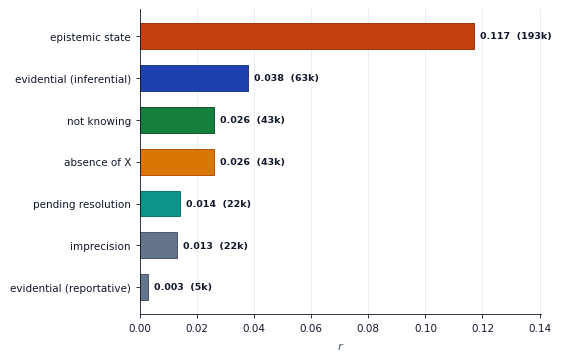

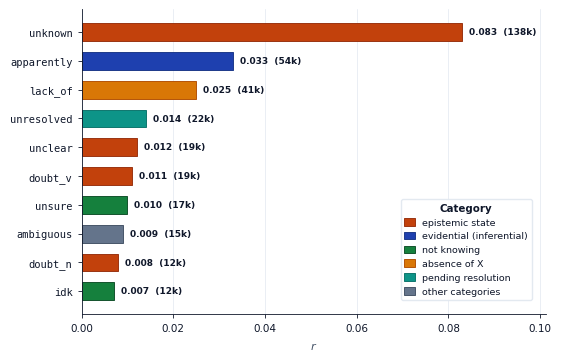

→ figures exported to notebooks/figs: fig_rq13a_top_subcategories, fig_rq13b_top_rules (.pdf + .png)


,rule_id,subcategory,n,units,rate_per_1k_tokens,se_native
0,lex.unknown,epistemic_state,137575,81870,0.083,False
1,lex.apparently,evidential_inferential,54233,52846,0.033,False
2,lex.lack_of,absence_of_X,41164,39349,0.025,False
3,lex.unresolved,pending_resolution,22349,14086,0.014,False
4,lex.unclear,epistemic_state,19314,18836,0.012,False
5,lex.doubt_v,epistemic_state,18792,18563,0.011,False
6,lex.unsure,not_knowing,16666,16365,0.010,False
7,lex.ambiguous,imprecision,14585,12175,0.009,False
8,lex.doubt_n,epistemic_state,12418,12049,0.008,False
9,lex.idk,not_knowing,11968,11463,0.007,False


In [ ]:
# RQ1.3 — Two publication-grade figures (split for independent placement in the paper):
#   (a) Top-10 lexical NK subcategories, token-normalised (rate per 1k tokens)
#   (b) Top-25 individual markers (rule level), colour-coded by subcategory
#
# Denominator note (v0.3.1): these figures are the corpus-wide INVENTORY view
# for the framework section; rates use pooled in-scope tokens (TOTAL_TOKENS,
# incl. NumFOCUS title tokens). Per-genre rates are reported in RQ1.1/RQ1.4 —
# do not read these bars as a per-genre claim.
#
# Palette & Design Language:
# Follows the editorial CVD-safe palette established in eda_curated_datasets.ipynb
# (CHANGELOG 2026-08-30):
#   - 5 primary hue anchors for the 5 dominant theoretical subcategories:
#       plausibility_shield -> Warm Rust (#C2410C)
#       not_knowing         -> Deep Navy (#1E40AF)
#       epistemic_state     -> Forest Pine (#15803D)
#       evidential          -> Amber Ochre (#D97706)
#       absence_of_X (5th)  -> Deep Teal (#0D9488)   [repro_gap retired 2026-09-21]
#   - Monotonic Slate (#64748B) for the remaining tail subcategories
#   - Open editorial frame (no top/right spine, subtle x-grid, outward ticks, direct data labels)

from pathlib import Path
import matplotlib.patches as mpatches

# ── 1. Data Retrieval: Top-25 Rules & Subcategory Aggregates ─────────────────
rq1_rules = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:HAS_SIGNAL]->(s:Signal {layer: 'lexical'})
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
  AND s.rule_version = $rule_version
  AND s.rule_id IN $active_rules
  AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.uncharted' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'terra')
  AND NOT coalesce(s.subcategory, '') IN $non_nk
RETURN s.rule_id AS rule_id, s.subcategory AS subcategory,
       count(*) AS n, count(DISTINCT u) AS units
ORDER BY n DESC LIMIT 10
""", corpora=IN_SCOPE_CORPORA, non_nk=NON_NK_SUBCATS, rule_version=V,
      active_rules=ACTIVE_RULE_IDS)

if not len(rq1_rules):
    rq1_rules = pd.DataFrame(columns=["rule_id", "subcategory", "n", "units"])

rq1_rules["rate_per_1k_tokens"] = (1000 * rq1_rules["n"] / TOTAL_TOKENS).round(3)
rq1_rules["se_native"] = rq1_rules["subcategory"].isin(SE_NATIVE_LEX)

rq1_subcats = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:HAS_SIGNAL]->(s:Signal {layer: 'lexical'})
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
  AND s.rule_version = $rule_version
  AND s.rule_id IN $active_rules
  AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.uncharted' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'terra')
  AND NOT coalesce(s.subcategory, '') IN $non_nk
RETURN s.subcategory AS subcategory,
       count(*) AS signals, count(DISTINCT u) AS units
ORDER BY signals DESC
""", corpora=IN_SCOPE_CORPORA, non_nk=NON_NK_SUBCATS, rule_version=V,
      active_rules=ACTIVE_RULE_IDS)

if not len(rq1_subcats):
    rq1_subcats = pd.DataFrame(columns=["subcategory", "signals", "units"])

rq1_subcats["rate_per_1k_tokens"] = (1000 * rq1_subcats["signals"] / TOTAL_TOKENS).round(3)
rq1_subcats["se_native"] = rq1_subcats["subcategory"].isin(SE_NATIVE_LEX)

# 5 distinctive, CVD-safe editorial hues for the 5 primary subcategories
TOP5_HUES = [
    ("#C2410C", "#9A3412"),   # Warm Rust (plausibility_shield)
    ("#1E40AF", "#1E3A8A"),   # Deep Navy (not_knowing)
    ("#15803D", "#14532D"),   # Forest Pine (epistemic_state)
    ("#D97706", "#B45309"),   # Amber Ochre (evidential_inferential)
    ("#0D9488", "#0F766E"),   # Deep Teal (5th-ranked subcategory; repro_gap retired)
]
OTHER_HUE = ("#64748B", "#475569")  # Slate for remaining tail subcategories

subcat_order = rq1_subcats["subcategory"].tolist()
TOP5_SUBCATS = subcat_order[:5]

SUBCAT_PALETTE = {}
SUBCAT_DARK_PALETTE = {}
for i, sc in enumerate(subcat_order):
    if i < 5:
        SUBCAT_PALETTE[sc], SUBCAT_DARK_PALETTE[sc] = TOP5_HUES[i]
    else:
        SUBCAT_PALETTE[sc], SUBCAT_DARK_PALETTE[sc] = OTHER_HUE

def format_subcat_label(sc: str, se_native: bool = False) -> str:
    mapping = {
        "plausibility_shield": "plausibility shield",
        "not_knowing": "not knowing",
        "epistemic_state": "epistemic state",
        "evidential_inferential": "evidential (inferential)",
        #"repro_gap": "reproduction gap",
        "absence_of_X": "absence of X",
        #"non_deterministic_behaviour": "non-deterministic behaviour",
        #"pending_resolution": "pending resolution",
        #"spec_gap": "specification gap",
        "imprecision": "imprecision",
        #"attribution_shield": "attribution shield",
        "evidential_reportative": "evidential (reportative)",
        #"opacity": "opacity",
        #"visibility_metaphor": "visibility metaphor",
        #"gap_phrase": "gap phrase",
    }
    lbl = mapping.get(sc, sc.replace("_", " "))
    if se_native:
        lbl += " †"
    return lbl

def _apply_figure_spines(ax: plt.Axes) -> None:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(INK)
    ax.spines["left"].set_linewidth(0.6)
    ax.spines["bottom"].set_color(INK)
    ax.spines["bottom"].set_linewidth(0.6)
    ax.tick_params(colors=INK, labelsize=7.5, direction="out", length=3, width=0.6)
    ax.xaxis.grid(True, color=LINE, linewidth=0.5, linestyle="-", zorder=0)
    ax.set_axisbelow(True)

def _export_fig(fig: plt.Figure, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=300)

# ── 3. Figure (a): Top-10 Lexical Subcategories ──────────────────────────────
top10_subcats = rq1_subcats.head(10).copy()
if len(top10_subcats):
    top10_plot = top10_subcats.iloc[::-1].reset_index(drop=True)
    fig_a, ax_a = plt.subplots(figsize=(5.5, 3.5), layout="constrained")
    y_pos_a = np.arange(len(top10_plot))
    
    ax_a.barh(
        y_pos_a, top10_plot["rate_per_1k_tokens"],
        color=[SUBCAT_PALETTE[s] for s in top10_plot["subcategory"]],
        edgecolor=[SUBCAT_DARK_PALETTE[s] for s in top10_plot["subcategory"]],
        linewidth=0.7, height=0.62, zorder=2
    )
    ax_a.set_yticks(y_pos_a)
    ax_a.set_yticklabels(
        [format_subcat_label(r.subcategory, r.se_native) for r in top10_plot.itertuples()],
        fontsize=7.8, color=INK
    )
    ax_a.set_xlabel(r"$r$", fontsize=8.2, color=GREY_TEXT, labelpad=5)
    xmax_a = top10_plot["rate_per_1k_tokens"].max() * 1.20
    ax_a.set_xlim(0, xmax_a)
    _apply_figure_spines(ax_a)
    
    for r, y in zip(top10_plot.itertuples(), y_pos_a):
        rate_str = f"{r.rate_per_1k_tokens:.3f}"
        count_str = f"({r.signals/1e3:.0f}k)" if r.signals >= 1e3 else f"({r.signals})"
        ax_a.text(r.rate_per_1k_tokens + xmax_a * 0.015, y,
                  f"{rate_str}  {count_str}",
                  va="center", ha="left", fontsize=6.8, color=INK, fontweight="semibold")
    
    #ax_a.set_title("(a) Top-10 Lexical Non-Knowledge Subcategories",
    #               fontsize=8.8, fontweight="bold", pad=8, color=INK, loc="left")
    # ax_a.text(0.99, 0.05, "† SE-native subcategory (absent from source taxonomies)",
    #           transform=ax_a.transAxes, ha="right", va="bottom", fontsize=6.2,
    #           color=GREY_TEXT, style="italic")
    
    _export_fig(fig_a, "fig_rq13a_top_subcategories")
    plt.show()

# ── 4. Figure (b): Top-10 Lexical Rules (Colour-Coded by Subcategory) ────────
if len(rq1_rules):
    rules_plot = rq1_rules.iloc[::-1].reset_index(drop=True)
    fig_b, ax_b = plt.subplots(figsize=(5.5, 3.5), layout="constrained")
    y_pos_b = np.arange(len(rules_plot))
    
    ax_b.barh(
        y_pos_b, rules_plot["rate_per_1k_tokens"],
        color=[SUBCAT_PALETTE.get(s, OTHER_HUE[0]) for s in rules_plot["subcategory"]],
        edgecolor=[SUBCAT_DARK_PALETTE.get(s, OTHER_HUE[1]) for s in rules_plot["subcategory"]],
        linewidth=0.7, height=0.62, zorder=2
    )
    ax_b.set_yticks(y_pos_b)
    
    rule_labels = []
    for r in rules_plot.itertuples():
        clean_id = r.rule_id.removeprefix("lex.")
        if r.se_native:
            clean_id += " †"
        rule_labels.append(clean_id)
    
    ax_b.set_yticklabels(rule_labels, fontsize=7.6, family="monospace", color=INK)
    ax_b.set_xlabel(r"$r$", fontsize=8.2, color=GREY_TEXT, labelpad=5)
    xmax_b = rules_plot["rate_per_1k_tokens"].max() * 1.22
    ax_b.set_xlim(0, xmax_b)
    _apply_figure_spines(ax_b)
    
    for r, y in zip(rules_plot.itertuples(), y_pos_b):
        rate_str = f"{r.rate_per_1k_tokens:.3f}"
        count_str = f"({r.n/1e3:.0f}k)" if r.n >= 1e3 else f"({r.n})"
        ax_b.text(r.rate_per_1k_tokens + xmax_b * 0.015, y,
                  f"{rate_str}  {count_str}",
                  va="center", ha="left", fontsize=6.5, color=INK, fontweight="semibold")
    
    #ax_b.set_title("(b) Top-25 Lexical NK Markers (Rule Level, Colour-Coded by Subcategory)",
    #               fontsize=8.8, fontweight="bold", pad=8, color=INK, loc="left")
    
    legend_handles = [
        mpatches.Patch(facecolor=SUBCAT_PALETTE[s], edgecolor=SUBCAT_DARK_PALETTE[s],
                       label=format_subcat_label(s, s in SE_NATIVE_LEX), linewidth=0.7)
        for s in TOP5_SUBCATS
    ]
    legend_handles.append(
        mpatches.Patch(facecolor=OTHER_HUE[0], edgecolor=OTHER_HUE[1],
                       label="other categories", linewidth=0.7)
    )
    
    leg = ax_b.legend(
        handles=legend_handles, title="Category",
        loc="lower right", bbox_to_anchor=(0.98, 0.03),
        fontsize=6.8, title_fontsize=7.4, frameon=True,
        facecolor="white", edgecolor=LINE, framealpha=0.95,
        handlelength=1.1, handleheight=0.9, labelcolor=INK
    )
    leg.get_title().set_fontweight("bold")
    leg.get_title().set_color(INK)
    
    #_export_fig(fig_b, "fig_rq13b_top_rules")
    plt.show()

print(f"→ figures exported to {FIG_DIR.relative_to(ROOT)}: "
      "fig_rq13a_top_subcategories, fig_rq13b_top_rules (.pdf + .png)")

# Return / display the top rules table
rq1_rules


In [10]:
top10_subcats

,subcategory,signals,units,rate_per_1k_tokens,se_native
0,epistemic_state,192908,135374,0.117,False
1,evidential_inferential,62598,60913,0.038,False
2,not_knowing,43458,42456,0.026,False
3,absence_of_X,42732,40707,0.026,False
4,pending_resolution,22349,14086,0.014,False
5,imprecision,22043,19440,0.013,False
6,evidential_reportative,5257,5120,0.003,False


In [11]:
# RQ1.4 — Per-corpus and per-genre normalised lexical rates.
# v0.2 attributed units through (Repository|MailingList)-[:CONTAINS]->(artefact);
# 02b attributes through the artefact's corpus_id directly.
rq1_src = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
OPTIONAL MATCH (u)-[:HAS_SIGNAL]->(s:Signal {layer: 'lexical'})
WHERE s.rule_version = $rule_version
  AND s.rule_id IN $active_rules
  AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.uncharted' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'terra')
  AND NOT coalesce(s.subcategory, '') IN $non_nk
RETURN coalesce(p.corpus_id, '') AS corpus,
       count(DISTINCT u) AS units,
       count(DISTINCT CASE WHEN s IS NOT NULL THEN u END) AS lexical_units,
       count(s) AS lexical_signals
ORDER BY units DESC
""", corpora=IN_SCOPE_CORPORA, non_nk=NON_NK_SUBCATS, rule_version=V,
      active_rules=ACTIVE_RULE_IDS)

if not len(rq1_src):
    rq1_src = pd.DataFrame(columns=["corpus", "units", "lexical_units", "lexical_signals"])
rq1_src["tokens"] = rq1_src.corpus.map(CORPUS_TOKENS).fillna(0).astype(int)
rq1_src["genre"] = rq1_src.corpus.map(genre_of)
rq1_src["units_per_1k_units"]     = (1000 * rq1_src.lexical_units / rq1_src.units.replace(0, np.nan)).round(1)
rq1_src["signals_per_1k_tokens"]  = (1000 * rq1_src.lexical_signals / rq1_src.tokens.replace(0, np.nan)).round(3)
rq1_src["mean_tokens_per_unit"]   = (rq1_src.tokens / rq1_src.units.replace(0, np.nan)).round(1)
print("Per corpus — if the two rate columns rank corpora differently, the per-unit")
print("ranking is reporting unit length, not NK density.")
display(rq1_src[["corpus", "genre", "units", "tokens", "mean_tokens_per_unit",
                 "units_per_1k_units", "signals_per_1k_tokens"]])

print("\nPer genre (token-normalised — the figure to report):")
per_genre_rate = (rq1_src.groupby("genre", as_index=False)
                   .agg(units=("units", "sum"), tokens=("tokens", "sum"),
                        lexical_units=("lexical_units", "sum"),
                        lexical_signals=("lexical_signals", "sum")))
per_genre_rate["signals_per_1k_tokens"] = (1000 * per_genre_rate.lexical_signals
                                           / per_genre_rate.tokens.replace(0, np.nan)).round(3)
per_genre_rate["units_per_1k_units"] = (1000 * per_genre_rate.lexical_units
                                        / per_genre_rate.units.replace(0, np.nan)).round(1)
display(per_genre_rate[["genre", "units", "tokens", "units_per_1k_units", "signals_per_1k_tokens"]])


Per corpus — if the two rate columns rank corpora differently, the per-unit
ranking is reporting unit length, not NK density.


,corpus,genre,units,tokens,mean_tokens_per_unit,units_per_1k_units,signals_per_1k_tokens
0,curated-email-code-reviews,email,14561855,543359540,37.3,5.6,0.183
1,alternative-jira,tracker,14006542,787303749,56.2,10.1,0.238
2,gittercom,chat,2950192,38080515,12.9,4.2,0.335
3,apache-jira,tracker,2207299,113823637,51.6,9.5,0.289
4,livechat-gitter,chat,1649133,19614925,11.9,4.6,0.401
5,sotorrent,qa,1613250,95781465,59.4,14.0,0.253
6,disco,chat,1427726,11670353,8.2,7.0,0.864
7,openment,tracker,1335605,36865064,27.6,10.8,0.413
8,numfocus,tracker,332983,2169654,6.5,1.8,0.271
9,preethac-slack,chat,209769,3230218,15.4,5.5,0.362



Per genre (token-normalised — the figure to report):


,genre,units,tokens,units_per_1k_units,signals_per_1k_tokens
0,chat,6276230,73018228,5.0,0.439
1,email,14561855,543359540,5.6,0.183
2,qa,1613250,95781465,14.0,0.253
3,tracker,17882429,940162104,9.9,0.251


In [29]:
# RQ1.5 — Corpus- and Genre-specific normalised lexical rates.
# ── 1. Data Retrieval: Top-25 Rules & Subcategory Aggregates ─────────────────

CORPUS = ["disco"]

rq1_5_rules = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:HAS_SIGNAL]->(s:Signal {layer: 'lexical'})
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
  AND s.rule_version = $rule_version
  AND s.rule_id IN $active_rules
  AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.uncharted' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'terra')
  AND NOT coalesce(s.subcategory, '') IN $non_nk
RETURN s.rule_id AS rule_id, s.subcategory AS subcategory,
       count(*) AS n, count(DISTINCT u) AS units
ORDER BY n DESC LIMIT 10
""", corpora=CORPUS, non_nk=NON_NK_SUBCATS, rule_version=V,
      active_rules=ACTIVE_RULE_IDS)

if not len(rq1_5_rules):
    rq1_5_rules = pd.DataFrame(columns=["rule_id", "subcategory", "n", "units"])

rq1_5_rules["rate_per_1k_tokens"] = (1000 * rq1_5_rules["n"] / CORPUS_TOKENS[CORPUS[0]]).round(3)
rq1_5_rules["se_native"] = rq1_5_rules["subcategory"].isin(SE_NATIVE_LEX)

rq1_5_subcats = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:HAS_SIGNAL]->(s:Signal {layer: 'lexical'})
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
  AND s.rule_version = $rule_version
  AND s.rule_id IN $active_rules
  AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.uncharted' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'terra')
  AND NOT coalesce(s.subcategory, '') IN $non_nk
RETURN s.subcategory AS subcategory,
       count(*) AS signals, count(DISTINCT u) AS units
ORDER BY signals DESC
""", corpora=CORPUS, non_nk=NON_NK_SUBCATS, rule_version=V,
      active_rules=ACTIVE_RULE_IDS)

if not len(rq1_5_subcats):
    rq1_5_subcats = pd.DataFrame(columns=["subcategory", "signals", "units"])

rq1_5_subcats["rate_per_1k_tokens"] = (1000 * rq1_5_subcats["signals"] / CORPUS_TOKENS[CORPUS[0]]).round(3)
rq1_5_subcats["se_native"] = rq1_5_subcats["subcategory"].isin(SE_NATIVE_LEX)

In [30]:
rq1_5_rules

,rule_id,subcategory,n,units,rate_per_1k_tokens,se_native
0,lex.idk,not_knowing,6105,6067,0.523,False
1,lex.apparently,evidential_inferential,920,917,0.079,False
2,lex.doubt_v,epistemic_state,585,584,0.050,False
3,lex.who_knows,not_knowing,460,459,0.039,False
4,lex.doubt_n,epistemic_state,374,372,0.032,False
5,lex.lack_of,absence_of_X,305,305,0.026,False
6,lex.vague,imprecision,243,240,0.021,False
7,lex.unknown,epistemic_state,239,232,0.020,False
8,lex.unsure,not_knowing,197,194,0.017,False
9,lex.unclear,epistemic_state,107,107,0.009,False


In [31]:
rq1_5_subcats

,subcategory,signals,units,rate_per_1k_tokens,se_native
0,not_knowing,6967,6923,0.597,False
1,epistemic_state,1358,1347,0.116,False
2,evidential_inferential,996,993,0.085,False
3,imprecision,314,311,0.027,False
4,absence_of_X,312,312,0.027,False
5,evidential_reportative,74,74,0.006,False
6,pending_resolution,61,61,0.005,False


---
## RQ2 · Baseline 2b — Morpho-syntactic encoding & the **cue-vs-scope gap** *(descriptive framework)*
**Question.** How much NK is encoded by construction rather than keyword — the
**cue-vs-scope gap** between bare-token and scoped (DependencyMatcher) rules
(`REFINED_RQS_v0.3.md` §3, Baseline 2b)?

**Headline metric (v0.3.1).** The share of morpho-syntactic NK carried by scoped
constructions, **per genre**, token-normalised, computed on ALL morpho signals —
classifier-independent (Baseline 2 is descriptive; the classifier never gates it,
per FRAMEWORK_DESIGN.md §1).

**Auxiliary diagnostic.** The classifier-positive 2×2 contingency (scoped-only /
cue-only / both / neither) is retained as a keyword-false-negative diagnostic on the
classifier's population; it is no longer the headline. The v0.2 pattern-file
corrections stay visible (epistemic vs `underspecified` modality; `scoped_epistemic`
vs `bare_negation` — never summed).

**Corpus scope.** All counts restricted to the curated corpora (§2.0 registry).

In [23]:
# RQ2.1 — Category × subcategory distribution, per genre (token-normalised).
# v0.3.1: the pooled-rate table is replaced by per-genre rates (GENRE_TOKENS).
# The avg_weight_INERT column is dropped: Signal.weight is inert (no figure in
# this notebook is weighted) and RQ5.4 owns the only accepted weight definition.
if GRAPH_EMPTY:
    print("RQ2.1 skipped (no in-scope signals — see Baseline 2.0).")
else:
    morph_active = sig[sig.layer == "morpho_syntactic"]
    mg = (morph_active.groupby(["category", "subcategory", "rule_id"], as_index=False)
          .agg(signals=("signals", "sum")))
    #CATEGORY_TOKENS   = mg.groupby("category").tokens.sum().astype(int).to_dict()
    mg["rate_per_1k_tokens"] = (1000 * mg.signals / TOTAL_TOKENS).round(3)
    print("── Active, per genre ──")
    display(mg.sort_values(["rate_per_1k_tokens"], ascending=[False]))

    m_cand = cand[(cand.layer == "morpho_syntactic") & (cand.status == "candidate")]
    if len(m_cand):
        print("\n── Candidate (report separately) ──")
        display(m_cand.groupby(["category", "subcategory", "rule_id"], as_index=False)
                .agg(signals=("signals", "sum"))
                .sort_values("signals", ascending=False))

── Active, per genre ──


,category,subcategory,rule_id,signals,rate_per_1k_tokens
2,evidential,inferential,morph.evid.inferential_seem,3220447,1.949
9,hedging,plausibility_shield,morph.hedge.shield_think,1895873,1.147
10,modality,epistemic,morph.mod.epistemic_maymight,1834478,1.110
5,hedging,adverbial,morph.hedge.adverbial_perhaps,791749,0.479
4,hedging,adverbial,morph.hedge.adverbial_maybe,749090,0.453
3,evidential,inferential,morph.evid.inferential_suggest,645901,0.391
12,negation,scoped_epistemic,morph.neg.scoped_epistemic,548747,0.332
0,epistemic_verb,not_knowing,morph.epi.neg_cognition,373721,0.226
17,tense,past_nk,morph.tense.past_nk_notyet,238396,0.144
11,modality,epistemic,morph.mod.epistemic_must_be,227059,0.137



── Candidate (report separately) ──


,category,subcategory,rule_id,signals
3,modality,underspecified,morph.mod.underspecified_cancould,10841323
5,syntactic_pattern,adversative,morph.syn.adversative,6329205
2,modality,epistemic_prediction,morph.mod.epistemic_will_predict,4750233
1,modality,deontic,morph.mod.deontic,4195553
4,negation,quantifier_no,morph.neg.nobody_nothing,338357
6,syntactic_pattern,embedded_question,morph.syn.i_wonder,48441
0,epistemic_verb,not_knowing_ascribed,morph.epi.neg_cognition_ascribed,2329


In [ ]:
645901+373721+338357+321047+238396+227059+215917+145435+67812

1540839

In [13]:
morph_active

,corpus,layer,category,subcategory,rule_id,signals,genre,se_native
0,disco,morpho_syntactic,negation,scoped_epistemic,morph.neg.scoped_epistemic,9679,chat,False
1,gittercom,morpho_syntactic,negation,scoped_epistemic,morph.neg.scoped_epistemic,36174,chat,False
2,gittercom,morpho_syntactic,hedging,plausibility_shield,morph.hedge.shield_think,113760,chat,False
3,gittercom,morpho_syntactic,tense,future_nk,morph.tense.future_nk_will_never,928,chat,False
4,gittercom,morpho_syntactic,epistemic_verb,not_knowing,morph.epi.neg_cognition,30832,chat,False
5,gittercom,morpho_syntactic,tense,past_nk,morph.tense.past_nk_notyet,11868,chat,False
6,gittercom,morpho_syntactic,evidential,inferential,morph.evid.inferential_seem,156911,chat,False
7,gittercom,morpho_syntactic,modality,epistemic,morph.mod.epistemic_must_be,5707,chat,False
8,gittercom,morpho_syntactic,modality,epistemic,morph.mod.epistemic_maymight,55819,chat,False
9,gittercom,morpho_syntactic,hedging,adverbial,morph.hedge.adverbial_maybe,43214,chat,False


In [14]:
# RQ2.2 — The families new in v0.2 of the pattern files (epistemic_verb,
# evidential, shields), reported separately per the refinement note, now
# per genre and token-normalised (v0.3.1 binding constraint).
if GRAPH_EMPTY:
    print("RQ2.2 skipped (no in-scope signals — see Baseline 2.0).")
else:
    fam = sig[(sig.layer == "morpho_syntactic")
              & (sig.category.isin(["epistemic_verb", "evidential"])
                 | sig.subcategory.isin(["plausibility_shield", "attribution_shield"]))]
    fg = (fam.groupby(["category", "subcategory", "id"], as_index=False)
          .agg(signals=("signals", "sum")))
    fg["rate_per_1k_tokens"] = (1000 * fg.signals / fg.genre.map(GENRE_TOKENS)).round(3)
    display(fg.sort_values(["genre", "signals"], ascending=[True, False]))

KeyError: 'id'

In [ ]:
# RQ2.4 — Per-corpus and per-genre normalised morpho rates.
# v0.2 attributed units through (Repository|MailingList)-[:CONTAINS]->(artefact);
# 02b attributes through the artefact's corpus_id directly.
rq2_src = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
OPTIONAL MATCH (u)-[:HAS_SIGNAL]->(s:Signal {layer: 'morpho_syntactic'})
WHERE s.rule_version = $rule_version
  AND s.rule_id IN $active_rules
  AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.uncharted' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'terra')
  AND NOT coalesce(s.subcategory, '') IN $non_nk
RETURN coalesce(p.corpus_id, '') AS corpus,
       count(DISTINCT u) AS units,
       count(DISTINCT CASE WHEN s IS NOT NULL THEN u END) AS morpho_units,
       count(s) AS morpho_signals
ORDER BY units DESC
""", corpora=IN_SCOPE_CORPORA, non_nk=NON_NK_SUBCATS, rule_version=V,
      active_rules=ACTIVE_RULE_IDS)

if not len(rq2_src):
    rq2_src = pd.DataFrame(columns=["corpus", "units", "morpho_units", "morpho_signals"])
rq2_src["tokens"] = rq2_src.corpus.map(CORPUS_TOKENS).fillna(0).astype(int)
rq2_src["genre"] = rq2_src.corpus.map(genre_of)
rq2_src["units_per_1k_units"]     = (1000 * rq2_src.morpho_units / rq2_src.units.replace(0, np.nan)).round(1)
rq2_src["signals_per_1k_tokens"]  = (1000 * rq2_src.morpho_signals / rq2_src.tokens.replace(0, np.nan)).round(3)
rq2_src["mean_tokens_per_unit"]   = (rq2_src.tokens / rq2_src.units.replace(0, np.nan)).round(1)
print("Per corpus — if the two rate columns rank corpora differently, the per-unit")
print("ranking is reporting unit length, not NK density.")
display(rq2_src[["corpus", "genre", "units", "tokens", "mean_tokens_per_unit",
                 "units_per_1k_units", "signals_per_1k_tokens"]])

print("\nPer genre (token-normalised — the figure to report):")
per_genre_rate = (rq2_src.groupby("genre", as_index=False)
                   .agg(units=("units", "sum"), tokens=("tokens", "sum"),
                        morpho_units=("morpho_units", "sum"),
                        morpho_signals=("morpho_signals", "sum")))
per_genre_rate["signals_per_1k_tokens"] = (1000 * per_genre_rate.morpho_signals
                                           / per_genre_rate.tokens.replace(0, np.nan)).round(3)
per_genre_rate["units_per_1k_units"] = (1000 * per_genre_rate.morpho_units
                                        / per_genre_rate.units.replace(0, np.nan)).round(1)
display(per_genre_rate[["genre", "units", "tokens", "units_per_1k_units", "signals_per_1k_tokens"]])


Per corpus — if the two rate columns rank corpora differently, the per-unit
ranking is reporting unit length, not NK density.


,corpus,genre,units,tokens,mean_tokens_per_unit,units_per_1k_units,signals_per_1k_tokens
0,curated-email-code-reviews,email,14561855,543359540,37.3,96.5,5.015
1,alternative-jira,tracker,14006542,787303749,56.2,227.7,6.710
2,gittercom,chat,2950192,38080515,12.9,151.1,14.118
3,apache-jira,tracker,2207299,113823637,51.6,141.4,4.514
4,livechat-gitter,chat,1649133,19614925,11.9,131.6,12.996
5,sotorrent,qa,1613250,95781465,59.4,325.3,10.099
6,disco,chat,1427726,11670353,8.2,88.6,12.127
7,openment,tracker,1335605,36865064,27.6,228.0,12.709
8,numfocus,tracker,332983,2169654,6.5,7.7,1.201
9,preethac-slack,chat,209769,3230218,15.4,205.2,16.742



Per genre (token-normalised — the figure to report):


,genre,units,tokens,units_per_1k_units,signals_per_1k_tokens
0,chat,6276230,73018228,133.3,13.605
1,email,14561855,543359540,96.5,5.015
2,qa,1613250,95781465,325.3,10.099
3,tracker,17882429,940162104,213.0,6.667


In [ ]:
# RQ2.3 — AUXILIARY diagnostic (v0.3.1): the cue-vs-scope contingency on
# classifier-positive units. The Baseline 2b headline is RQ2.4b below
# (scoped share of ALL morpho signals, classifier-independent); this 2×2
# stays as a keyword-false-negative check on the classifier's population.
rq2_gap = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:CLASSIFIED_AS]->(v:ClassifierVerdict)
WHERE v.label = 1 AND @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
OPTIONAL MATCH (u)-[:HAS_SIGNAL]->(s:Signal {layer: 'morpho_syntactic'})
WHERE s.rule_version = $rule_version
  AND s.rule_id IN $active_rules
  AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.uncharted' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'terra')
WITH u, collect(DISTINCT s.rule_id) AS rules
WITH u,
     any(r IN rules WHERE r IN $scoped)                        AS has_scoped,
     any(r IN rules WHERE NOT r IN $scoped AND r IS NOT NULL)  AS has_cue
RETURN has_scoped, has_cue, count(*) AS units
""", corpora=IN_SCOPE_CORPORA, scoped=SCOPED_RULES, rule_version=V, active_rules=ACTIVE_RULE_IDS)

pivot = rq2_gap.pivot_table(index="has_scoped", columns="has_cue",
                            values="units", fill_value=0)
total_pos = int(pivot.values.sum()) if len(pivot) else 0


def cell(i, c):
    try:
        return int(pivot.loc[i, c])
    except KeyError:
        return 0


scoped_only = cell(True, False)
print(f"Classifier-positive units: {total_pos:,}")
if total_pos:
    p, lo, hi = wilson(scoped_only, total_pos)
    print(f"SCOPED-ONLY morpho evidence: {scoped_only:,} ({p:.1%} [{lo:.1%}, {hi:.1%}])")
    print("→ NK invisible to any keyword list: the empirical justification for the")
    print("  scope-aware pattern design, and RQ2's headline contribution.")
pivot


Classifier-positive units: 9,846,345
SCOPED-ONLY morpho evidence: 339,860 (3.5% [3.4%, 3.5%])
→ NK invisible to any keyword list: the empirical justification for the
  scope-aware pattern design, and RQ2's headline contribution.


has_cue,False,True
has_scoped,,
False,2711862.0,5296774.0
True,339860.0,1497849.0


In [ ]:
# RQ2.4 — Which scoped constructions do the work? (name them in the paper)
q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
WHERE s.rule_id IN $scoped AND @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
  AND s.rule_version = $rule_version AND s.rule_id IN $active_rules
  AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.uncharted' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'terra')
RETURN s.rule_id AS rule_id, count(*) AS signals, count(DISTINCT u) AS units,
       collect(DISTINCT s.surface_form)[..5] AS sample_surface_forms
ORDER BY signals DESC
""", corpora=IN_SCOPE_CORPORA, scoped=SCOPED_RULES, rule_version=V,
      active_rules=ACTIVE_RULE_IDS)


,rule_id,signals,units,sample_surface_forms
0,morph.hedge.shield_think,1890508,1521182,"[I think I will go, I think I've improved, I g..."
1,morph.epi.neg_cognition,373721,354038,"[I didn't know, I don't know, I don't get, i d..."
2,morph.neg.scoped_epistemic,321047,308351,"[Not sure, not sure, no knowledge, no idea, No..."
3,morph.tense.past_nk_notyet,238396,211240,"[n't exist yet, n't tried reitit yet, n't unde..."
4,morph.epi.neg_cognition_modal,65742,62414,"[cant you say, can't say, wouldn't have figure..."


In [ ]:
# RQ2.4b — THE cue-vs-scope gap, per genre (the Baseline 2b headline metric).
# Descriptive and classifier-independent: the share of morpho-syntactic NK that is
# carried by scoped (DependencyMatcher) constructions, per genre, token-normalised.
# The classifier-positive contingency (RQ2.3/RQ2.5) is an auxiliary diagnostic of
# keyword-list false negatives on the classifier's population; THIS cell is the
# reportable headline (RESULTS_AND_DISCUSSION_v0.3.md §2.2: e.g. chat 11.1%, QA 6.1%).
if GRAPH_EMPTY:
    print("RQ2.4b skipped (no in-scope signals — see Baseline 2.0).")
else:
    morph = sig[sig.layer == "morpho_syntactic"].copy()
    morph["scoped"] = morph.rule_id.isin(SCOPED_RULES)
    rows = []
    for (genre, scoped), g in morph.groupby(["genre", "scoped"]):
        n = int(g.signals.sum())
        toks = sum(CORPUS_TOKENS.get(c, 0) for c in g.corpus.unique())
        rows.append({"genre": genre, "scoped": bool(scoped), "signals": n,
                     "rate_per_1k_tokens": 1000 * n / toks if toks else float("nan")})
    ms = pd.DataFrame(rows)
    print("RQ2.4b · Morpho-syntactic signals by genre and scope-type (per 1k tokens):")
    display(ms.pivot(index="genre", columns="scoped", values="rate_per_1k_tokens"))

    gap = (ms[ms.scoped].set_index("genre").rate_per_1k_tokens
           .div(ms.groupby("genre").rate_per_1k_tokens.sum())).dropna()
    print("\nCue-vs-scope gap (share of morpho NK carried by scoped constructions):")
    display(gap.to_frame("scoped_share"))

RQ2.4b · Morpho-syntactic signals by genre and scope-type (per 1k tokens):


scoped,False,True
genre,,
chat,9.246253,4.910459
email,4.083069,1.620474
qa,7.965236,2.520613
tracker,5.063969,1.570933



Cue-vs-scope gap (share of morpho NK carried by scoped constructions):


,scoped_share
genre,
chat,0.346864
email,0.284117
qa,0.240382
tracker,0.236768


In [ ]:
# RQ2.5 — AUXILIARY, per genre (v0.3.1): the classifier-positive cue-vs-scope
# contingency per genre. The headline per-genre metric is RQ2.4b below.
rq2_gap_genre = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:CLASSIFIED_AS]->(v:ClassifierVerdict)
WHERE v.label = 1 AND @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
OPTIONAL MATCH (u)-[:HAS_SIGNAL]->(s:Signal {layer: 'morpho_syntactic'})
WHERE s.rule_version = $rule_version
  AND s.rule_id IN $active_rules
  AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.uncharted' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'terra')
WITH coalesce(p.corpus_id, '') AS corpus, u, collect(DISTINCT s.rule_id) AS rules
WITH corpus, u,
     any(r IN rules WHERE r IN $scoped)                        AS has_scoped,
     any(r IN rules WHERE NOT r IN $scoped AND r IS NOT NULL)  AS has_cue
RETURN corpus, has_scoped, has_cue, count(*) AS units
""", corpora=IN_SCOPE_CORPORA, scoped=SCOPED_RULES, rule_version=V, active_rules=ACTIVE_RULE_IDS)

if len(rq2_gap_genre):
    rq2_gap_genre["genre"] = rq2_gap_genre.corpus.map(genre_of)
    rows = []
    for genre, g in rq2_gap_genre.groupby("genre"):
        pv = g.pivot_table(index="has_scoped", columns="has_cue", values="units", fill_value=0)
        def _c(i, j):
            try:
                return int(pv.loc[i, j])
            except KeyError:
                return 0
        tot = int(pv.values.sum())
        so = _c(True, False)
        p, lo, hi = wilson(so, tot) if tot else (float("nan"),) * 3
        rows.append({"genre": genre, "clf_pos_units": tot, "scoped_only": so,
                     "share": f"{p:.1%}" if tot else "n/a",
                     "ci": f"[{lo:.1%}, {hi:.1%}]" if tot else ""})
    display(pd.DataFrame(rows))
    print("\n→ the scoped-only share is the share of morpho NK on classifier-positive units")
    print("  that no bare keyword list could catch, per communicative genre.")
else:
    print("No classifier-positive units yet — annotate, then re-run.")


In [26]:
# RQ2.6 — Corpus- and Genre-specific normalised lexical rates.
# ── 1. Data Retrieval: Top-25 Rules & Subcategory Aggregates ─────────────────

CORPUS = ["disco"]

rq2_6_rules = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:HAS_SIGNAL]->(s:Signal {layer: 'morpho_syntactic'})
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
  AND s.rule_version = $rule_version
  AND s.rule_id IN $active_rules
  AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.uncharted' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'terra')
  AND NOT coalesce(s.subcategory, '') IN $non_nk
RETURN s.rule_id AS rule_id, s.subcategory AS subcategory,
       count(*) AS n, count(DISTINCT u) AS units
ORDER BY n DESC LIMIT 10
""", corpora=CORPUS, non_nk=NON_NK_SUBCATS, rule_version=V,
      active_rules=ACTIVE_RULE_IDS)

if not len(rq2_6_rules):
    rq2_6_rules = pd.DataFrame(columns=["rule_id", "subcategory", "n", "units"])

rq2_6_rules["rate_per_1k_tokens"] = (1000 * rq2_6_rules["n"] / CORPUS_TOKENS[CORPUS[0]]).round(3)
rq2_6_rules["se_native"] = rq2_6_rules["subcategory"].isin(SE_NATIVE_LEX)

rq2_6_subcats = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:HAS_SIGNAL]->(s:Signal {layer: 'morpho_syntactic'})
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
  AND s.rule_version = $rule_version
  AND s.rule_id IN $active_rules
  AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.uncharted' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'terra')
  AND NOT coalesce(s.subcategory, '') IN $non_nk
RETURN s.subcategory AS subcategory,
       count(*) AS signals, count(DISTINCT u) AS units
ORDER BY signals DESC
""", corpora=CORPUS, non_nk=NON_NK_SUBCATS, rule_version=V,
      active_rules=ACTIVE_RULE_IDS)

if not len(rq2_6_subcats):
    rq2_6_subcats = pd.DataFrame(columns=["subcategory", "signals", "units"])

rq2_6_subcats["rate_per_1k_tokens"] = (1000 * rq2_6_subcats["signals"] / CORPUS_TOKENS[CORPUS[0]]).round(3)
rq2_6_subcats["se_native"] = rq2_6_subcats["subcategory"].isin(SE_NATIVE_LEX)

In [27]:
rq2_6_rules

,rule_id,subcategory,n,units,rate_per_1k_tokens,se_native
0,morph.evid.inferential_seem,inferential,34967,33771,2.996,False
1,morph.hedge.shield_think,plausibility_shield,28247,27642,2.420,False
2,morph.mod.epistemic_maymight,epistemic,14168,13653,1.214,False
3,morph.hedge.adverbial_perhaps,adverbial,13629,13471,1.168,False
4,morph.epi.neg_cognition,not_knowing,13393,13225,1.148,False
5,morph.hedge.adverbial_maybe,adverbial,11344,11166,0.972,False
6,morph.neg.scoped_epistemic,scoped_epistemic,9679,9581,0.829,False
7,morph.hedge.approximator_kind_of,approximator,5949,5869,0.510,False
8,morph.evid.inferential_suggest,inferential,3416,3377,0.293,False
9,morph.tense.past_nk_notyet,past_nk,1860,1780,0.159,False


In [28]:
rq2_6_subcats 

,subcategory,signals,units,rate_per_1k_tokens,se_native
0,inferential,38383,36934,3.289,False
1,plausibility_shield,28247,27642,2.420,False
2,adverbial,24973,24456,2.140,False
3,epistemic,15394,14844,1.319,False
4,not_knowing,14933,13950,1.280,False
5,scoped_epistemic,9679,9581,0.829,False
6,approximator,7685,7575,0.659,False
7,past_nk,1860,1780,0.159,False
8,embedded_question,1192,1188,0.102,False
9,future_nk,507,504,0.043,False


---
## RQ3 · Baseline 2c — Rhetorical figures: SE-native vs canonical metaphors *(descriptive framework)*
**Question.** Which metaphor / comparison / personification families express NK, and do
SE-native figures (`opacity`, `hidden_extent`, `obscurity`) match the canonical
ignorance metaphors (blind spot, knowledge gap, uncharted territory — Simmerling &
Janich 2015) at comparable rates (`REFINED_RQS_v0.3.md` §3, Baseline 2c)?

**Operationalisation (v0.3.1).** `layer='rhetorical'` counts by family/subtype; the
**SE-native : canonical ratio per genre**, token-normalised. The `opacity`
double-count across Baseline 2a and 2c is disclosed, not silently avoided
(`FRAMEWORK_DESIGN.md` §1). All counts restricted to the curated corpora (§2.0).

In [ ]:
if GRAPH_EMPTY:
    print("RQ2.1 skipped (no in-scope signals — see Baseline 2.0).")
else:
    morph_active = sig[sig.layer == "morpho_syntactic"]
    mg = (morph_active.groupby(["category", "subcategory", "rule_id"], as_index=False)
          .agg(signals=("signals", "sum")))
    #CATEGORY_TOKENS   = mg.groupby("category").tokens.sum().astype(int).to_dict()
    mg["rate_per_1k_tokens"] = (1000 * mg.signals / TOTAL_TOKENS).round(3)
    print("── Active, per genre ──")
    display(mg.sort_values(["rate_per_1k_tokens"], ascending=[False]))

    m_cand = cand[(cand.layer == "morpho_syntactic") & (cand.status == "candidate")]
    if len(m_cand):
        print("\n── Candidate (report separately) ──")
        display(m_cand.groupby(["category", "subcategory", "rule_id"], as_index=False)
                .agg(signals=("signals", "sum"))
                .sort_values("signals", ascending=False))

In [19]:
# RQ3.1 — Family × subtype inventory + the per-genre SE-native vs canonical
# rates (token-normalised, v0.3.1 binding constraint). Inventory counts are
# active-only; the active+candidate upper bound lives in RQ3.2.
if GRAPH_EMPTY:
    print("RQ3.1 skipped (no in-scope signals — see Baseline 2.0).")
else:
    rhet_active = sig[sig.layer == "rhetorical"].copy()
    #rhet_active["se_native"] = rhet_active.subcategory.isin(SE_NATIVE_RHET)
    mg = (rhet_active.groupby(["category", "subcategory", "rule_id"], as_index=False)
        .agg(signals=("signals", "sum")))

    mg["rate_per_1k_tokens"] = (1000 * mg.signals / TOTAL_TOKENS).round(3)
    print("── Active, per genre ──")
    display(mg.sort_values(["rate_per_1k_tokens"], ascending=[False]))

    m_cand = cand[(cand.layer == "rhetorical") & (cand.status == "candidate")]
    if len(m_cand):
        print("\n── Candidate (report separately) ──")
        display(m_cand.groupby(["category", "subcategory", "rule_id"], as_index=False)
                .agg(signals=("signals", "sum"))
                .sort_values("signals", ascending=False))


    # print("── Family × subtype inventory (active) ──")
    # inv = (rhet_active.groupby(["category", "subcategory"], as_index=False)
    #        .agg(signals=("signals", "sum")).sort_values("signals", ascending=False)
    #        .rename(columns={"category": "family", "subcategory": "subtype"}))
    # display(inv)

    # rows = []
    # for (genre, se_nat), g in rhet_active.groupby(["genre", "se_native"]):
    #     n = int(g.signals.sum())
    #     toks = sum(CORPUS_TOKENS.get(c, 0) for c in g.corpus.unique())
    #     rows.append({"genre": genre, "se_native": bool(se_nat), "signals": n,
    #                  "rate_per_1k_tokens": 1000 * n / toks if toks else float("nan")})
    # rr = pd.DataFrame(rows)
    # print("\n── SE-native vs canonical, per genre (per 1k tokens) ──")
    # display(rr.pivot(index="genre", columns="se_native", values="rate_per_1k_tokens"))

── Active, per genre ──


,category,subcategory,rule_id,signals,rate_per_1k_tokens
0,comparison,approximator,rhetor.comparison.something_like,570523,0.345
4,metaphor,spatial_journey,rhetor.metaphor.spatial.uncharted,6796,0.004
2,metaphor,container,rhetor.metaphor.gap.missing_piece,2735,0.002
6,metaphor,visibility,rhetor.metaphor.visibility.dark,2127,0.001
1,metaphor,container,rhetor.metaphor.gap.knowledge_gap,51,0.000
3,metaphor,spatial_journey,rhetor.metaphor.spatial.new_territory,430,0.000
5,metaphor,visibility,rhetor.metaphor.visibility.blind_spot,178,0.000
7,personification,avoidance,rhetor.personification.elephant_room,54,0.000



── Candidate (report separately) ──


,category,subcategory,rule_id,signals
0,metaphor,visibility,rhetor.metaphor.visibility.overlook,10786
1,personification,poor_cousin,rhetor.personification.poor_cousin,10


In [20]:
# RQ2.4 — Per-corpus and per-genre normalised morpho rates.
# v0.2 attributed units through (Repository|MailingList)-[:CONTAINS]->(artefact);
# 02b attributes through the artefact's corpus_id directly.
rq3_src = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
OPTIONAL MATCH (u)-[:HAS_SIGNAL]->(s:Signal {layer: 'rhetorical'})
WHERE s.rule_version = $rule_version
  AND s.rule_id IN $active_rules
  AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.uncharted' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'terra')
  AND NOT coalesce(s.subcategory, '') IN $non_nk
RETURN coalesce(p.corpus_id, '') AS corpus,
       count(DISTINCT u) AS units,
       count(DISTINCT CASE WHEN s IS NOT NULL THEN u END) AS morpho_units,
       count(s) AS morpho_signals
ORDER BY units DESC
""", corpora=IN_SCOPE_CORPORA, non_nk=NON_NK_SUBCATS, rule_version=V,
      active_rules=ACTIVE_RULE_IDS)

if not len(rq3_src):
    rq3_src = pd.DataFrame(columns=["corpus", "units", "morpho_units", "morpho_signals"])
rq3_src["tokens"] = rq3_src.corpus.map(CORPUS_TOKENS).fillna(0).astype(int)
rq3_src["genre"] = rq3_src.corpus.map(genre_of)
rq3_src["units_per_1k_units"]     = (1000 * rq3_src.morpho_units / rq3_src.units.replace(0, np.nan)).round(1)
rq3_src["signals_per_1k_tokens"]  = (1000 * rq3_src.morpho_signals / rq3_src.tokens.replace(0, np.nan)).round(3)
rq3_src["mean_tokens_per_unit"]   = (rq3_src.tokens / rq3_src.units.replace(0, np.nan)).round(1)
print("Per corpus — if the two rate columns rank corpora differently, the per-unit")
print("ranking is reporting unit length, not NK density.")
display(rq3_src[["corpus", "genre", "units", "tokens", "mean_tokens_per_unit",
                 "units_per_1k_units", "signals_per_1k_tokens"]])

print("\nPer genre (token-normalised — the figure to report):")
per_genre_rate = (rq3_src.groupby("genre", as_index=False)
                   .agg(units=("units", "sum"), tokens=("tokens", "sum"),
                        morpho_units=("morpho_units", "sum"),
                        morpho_signals=("morpho_signals", "sum")))
per_genre_rate["signals_per_1k_tokens"] = (1000 * per_genre_rate.morpho_signals
                                           / per_genre_rate.tokens.replace(0, np.nan)).round(3)
per_genre_rate["units_per_1k_units"] = (1000 * per_genre_rate.morpho_units
                                        / per_genre_rate.units.replace(0, np.nan)).round(1)
display(per_genre_rate[["genre", "units", "tokens", "units_per_1k_units", "signals_per_1k_tokens"]])


Per corpus — if the two rate columns rank corpora differently, the per-unit
ranking is reporting unit length, not NK density.


,corpus,genre,units,tokens,mean_tokens_per_unit,units_per_1k_units,signals_per_1k_tokens
0,curated-email-code-reviews,email,14561855,543359540,37.3,7.2,0.209
1,alternative-jira,tracker,14006542,787303749,56.2,17.3,0.325
2,gittercom,chat,2950192,38080515,12.9,11.4,0.895
3,apache-jira,tracker,2207299,113823637,51.6,11.7,0.245
4,livechat-gitter,chat,1649133,19614925,11.9,10.3,0.879
5,sotorrent,qa,1613250,95781465,59.4,52.0,0.964
6,disco,chat,1427726,11670353,8.2,5.8,0.721
7,openment,tracker,1335605,36865064,27.6,20.5,0.773
8,numfocus,tracker,332983,2169654,6.5,0.1,0.023
9,preethac-slack,chat,209769,3230218,15.4,22.0,1.461



Per genre (token-normalised — the figure to report):


,genre,units,tokens,units_per_1k_units,signals_per_1k_tokens
0,chat,6276230,73018228,10.2,0.886
1,email,14561855,543359540,7.2,0.209
2,qa,1613250,95781465,52.0,0.964
3,tracker,17882429,940162104,16.6,0.332


In [ ]:
# RQ3.2 — SE-native : canonical ratio, per genre, shown BOTH ways: several
# SE-native figures ship as status='candidate' (pending calibration), so the
# honest comparison includes the active+candidate upper bound — same discipline
# as RQ1.2. Pooled-corpus ratio dropped (v0.3.1: no flat corpus means).
if GRAPH_EMPTY:
    print("RQ3.2 skipped (no in-scope signals — see Baseline 2.0).")
else:
    rhet_cand = cand[cand.layer == "rhetorical"].copy()
    rhet_cand["se_native"] = rhet_cand.subcategory.isin(SE_NATIVE_RHET)
    for status_filter, label in [(["active"], "active only"),
                                 (["active", "candidate"], "active+candidate")]:
        sub = rhet_cand[rhet_cand.status.isin(status_filter)]
        rows = []
        for genre, g in sub.groupby("genre"):
            se = int(g.loc[g.se_native, "signals"].sum())
            can = int(g.loc[~g.se_native, "signals"].sum())
            rows.append({"genre": genre, "se_native": se, "canonical": can,
                         "ratio": se / can if can else float("nan")})
        print(f"{label}:")
        display(pd.DataFrame(rows))

active only       : SE-native=   315  canonical=23,376  ratio=0.01
active+candidate  : SE-native=   625  canonical=23,637  ratio=0.03


In [ ]:
# RQ3.3 — Rhetorical density per genre, ACTIVE only, token-normalised (the
# register prediction the v0.2 notebook tested on arenas: discursive genres
# should carry more rhetorical NK than task-tracker genres). Candidate signals
# move to the RQ3.2 upper bound; the per_1k_units column is dropped — per-unit
# rates measured unit length, and token-normalisation is binding (v0.3.1).
if GRAPH_EMPTY:
    print("RQ3.3 skipped (no in-scope signals — see Baseline 2.0).")
else:
    rr2 = (sig[sig.layer == "rhetorical"].groupby("genre", as_index=False)
           .agg(signals=("signals", "sum")))
    rr2["per_1k_tokens"] = (1000 * rr2.signals / rr2.genre.map(GENRE_TOKENS)).round(4)
    print("Prediction: review_email & chat > tracker (discursive register).")
    display(rr2.sort_values("per_1k_tokens", ascending=False))

Prediction: review_email & chat > tracker (discursive register).


,genre,signals,per_1k_tokens
2,qa,92361,0.9643
0,chat,64691,0.8860
3,tracker,312517,0.3324
1,email,113332,0.2086


In [ ]:
# RQ3.4 — `opacity` appears as BOTH a lexical subcategory (RQ1) and a rhetorical
# subtype (RQ3). Per REFINED_RQS v0.2 the overlap is disclosed, not silently
# double-counted. Two distinct rule_ids on the same unit are two Signals by
# design — the issue is only that summing the RQ1 and RQ3 SE-native counts would
# count some units twice.
# 2026-09-21: the lexical opacity marker (black_box) was retired with the M-5
# revision, so only rhetorical opacity (black_box figure) can fire now — the
# overlap is expected to collapse to 0 and stays disclosed for exactly that
# reason.
overlap = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora AND s.rule_version = $rule_version
  AND s.subcategory = 'opacity'
  AND s.rule_id IN $active_rules
  AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.uncharted' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'terra')
RETURN s.layer AS layer, s.rule_id AS rule_id,
       count(*) AS signals, count(DISTINCT u) AS units
ORDER BY signals DESC
""", corpora=IN_SCOPE_CORPORA, rule_version=V, active_rules=ACTIVE_RULE_IDS)
display(overlap)
if len(overlap):
    oc = overlap.groupby("layer").signals.sum()
    print(f"Active 'opacity' signals — lexical: {int(oc.get('lexical', 0)):,}, "
          f"rhetorical: {int(oc.get('rhetorical', 0)):,} (never sum them).")

both = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
  AND EXISTS { MATCH (u)-[:HAS_SIGNAL]->(a:Signal)
               WHERE a.subcategory = 'opacity' AND a.layer = 'lexical'
                 AND a.rule_version = $rule_version AND a.rule_id IN $active_rules }
  AND EXISTS { MATCH (u)-[:HAS_SIGNAL]->(b:Signal)
               WHERE b.subcategory = 'opacity' AND b.layer = 'rhetorical'
                 AND b.rule_version = $rule_version AND b.rule_id IN $active_rules }
RETURN count(u) AS units_with_both
""", corpora=IN_SCOPE_CORPORA, rule_version=V, active_rules=ACTIVE_RULE_IDS)
n_both = int(both.iloc[0, 0]) if len(both) else 0
print(f"\nUnits carrying `opacity` in BOTH layers: {n_both:,}")
print("→ RQ1 counts these under lexical; RQ3 counts them under")
print("  rhetorical.opacity. Do not add the two SE-native totals together in the")
print("  paper without subtracting this figure.")


# RQ3.5 - Baseline 2d - Word formation layer

In [7]:
# RQ3.5 — Word formation - Category × subcategory distribution, per genre (token-normalised).
# v0.3.1: the pooled-rate table is replaced by per-genre rates (GENRE_TOKENS).
# The avg_weight_INERT column is dropped: Signal.weight is inert (no figure in
# this notebook is weighted) and RQ5.4 owns the only accepted weight definition.
if GRAPH_EMPTY:
    print("RQ2.1 skipped (no in-scope signals — see Baseline 2.0).")
else:
    morph_active = sig[sig.layer == "word_formation"]
    mg = (morph_active.groupby(["category", "subcategory", "rule_id"], as_index=False)
          .agg(signals=("signals", "sum")))
    #CATEGORY_TOKENS   = mg.groupby("category").tokens.sum().astype(int).to_dict()
    mg["rate_per_1k_tokens"] = (1000 * mg.signals / TOTAL_TOKENS).round(3)
    print("── Active, per genre ──")
    display(mg.sort_values(["rate_per_1k_tokens"], ascending=[False]))

    m_cand = cand[(cand.layer == "word_formation") & (cand.status == "candidate")]
    if len(m_cand):
        print("\n── Candidate (report separately) ──")
        display(m_cand.groupby(["category", "subcategory", "rule_id"], as_index=False)
                .agg(signals=("signals", "sum"))
                .sort_values("signals", ascending=False))

── Active, per genre ──


,category,subcategory,rule_id,signals,rate_per_1k_tokens


In [8]:
# RQ3.6 — Per-corpus and per-genre normalised word formation rates.
# v0.2 attributed units through (Repository|MailingList)-[:CONTAINS]->(artefact);
# 02b attributes through the artefact's corpus_id directly.
rq3_src = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
OPTIONAL MATCH (u)-[:HAS_SIGNAL]->(s:Signal {layer: 'word_formation'})
WHERE s.rule_version = $rule_version
  AND s.rule_id IN $active_rules
  AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.uncharted' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'terra')
  AND NOT coalesce(s.subcategory, '') IN $non_nk
RETURN coalesce(p.corpus_id, '') AS corpus,
       count(DISTINCT u) AS units,
       count(DISTINCT CASE WHEN s IS NOT NULL THEN u END) AS morpho_units,
       count(s) AS morpho_signals
ORDER BY units DESC
""", corpora=IN_SCOPE_CORPORA, non_nk=NON_NK_SUBCATS, rule_version=V,
      active_rules=ACTIVE_RULE_IDS)

if not len(rq3_src):
    rq3_src = pd.DataFrame(columns=["corpus", "units", "morpho_units", "morpho_signals"])
rq3_src["tokens"] = rq3_src.corpus.map(CORPUS_TOKENS).fillna(0).astype(int)
rq3_src["genre"] = rq3_src.corpus.map(genre_of)
rq3_src["units_per_1k_units"]     = (1000 * rq3_src.morpho_units / rq3_src.units.replace(0, np.nan)).round(1)
rq3_src["signals_per_1k_tokens"]  = (1000 * rq3_src.morpho_signals / rq3_src.tokens.replace(0, np.nan)).round(3)
rq3_src["mean_tokens_per_unit"]   = (rq3_src.tokens / rq3_src.units.replace(0, np.nan)).round(1)
print("Per corpus — if the two rate columns rank corpora differently, the per-unit")
print("ranking is reporting unit length, not NK density.")
display(rq3_src[["corpus", "genre", "units", "tokens", "mean_tokens_per_unit",
                 "units_per_1k_units", "signals_per_1k_tokens"]])

print("\nPer genre (token-normalised — the figure to report):")
per_genre_rate = (rq3_src.groupby("genre", as_index=False)
                   .agg(units=("units", "sum"), tokens=("tokens", "sum"),
                        morpho_units=("morpho_units", "sum"),
                        morpho_signals=("morpho_signals", "sum")))
per_genre_rate["signals_per_1k_tokens"] = (1000 * per_genre_rate.morpho_signals
                                           / per_genre_rate.tokens.replace(0, np.nan)).round(3)
per_genre_rate["units_per_1k_units"] = (1000 * per_genre_rate.morpho_units
                                        / per_genre_rate.units.replace(0, np.nan)).round(1)
display(per_genre_rate[["genre", "units", "tokens", "units_per_1k_units", "signals_per_1k_tokens"]])


Per corpus — if the two rate columns rank corpora differently, the per-unit
ranking is reporting unit length, not NK density.


,corpus,genre,units,tokens,mean_tokens_per_unit,units_per_1k_units,signals_per_1k_tokens
0,curated-email-code-reviews,email,14561855,543359540,37.3,0.0,0.0
1,alternative-jira,tracker,14006542,787303749,56.2,0.0,0.0
2,gittercom,chat,2950192,38080515,12.9,0.0,0.0
3,apache-jira,tracker,2207299,113823637,51.6,0.0,0.0
4,livechat-gitter,chat,1649133,19614925,11.9,0.0,0.0
5,sotorrent,qa,1613250,95781465,59.4,0.0,0.0
6,disco,chat,1427726,11670353,8.2,0.0,0.0
7,openment,tracker,1335605,36865064,27.6,0.0,0.0
8,numfocus,tracker,332983,2169654,6.5,0.0,0.0
9,preethac-slack,chat,209769,3230218,15.4,0.0,0.0



Per genre (token-normalised — the figure to report):


,genre,units,tokens,units_per_1k_units,signals_per_1k_tokens
0,chat,6276230,73018228,0.0,0.0
1,email,14561855,543359540,0.0,0.0
2,qa,1613250,95781465,0.0,0.0
3,tracker,17882429,940162104,0.0,0.0


---
# RQ3.7 — Genre & dataset composition of linguistic ignorance

*How is ignorance linguistically composed across the four communicative genres
(tracker, chat, Q&A, email) and the 11 curated datasets — and which
subcategories/rules set a genre apart?*

Two readings, two figures:

* **Fig A — composition (dominance):** what a genre's (and dataset's) NK is
  *mostly made of* — within-layer shares of NK signal hits.
* **Fig B — fingerprints (distinctiveness):** which subcategories are over- or
  under-represented versus the reference composition, and whether the datasets of
  a genre agree.

These figures are **rate-independent**: they say nothing about *how much*
ignorance a genre has (that is the r₁ₖ tables in RQ1/RQ2/RQ3), only what it is
made of. Layers are never pooled — each is its own composition (morpho counts
are ~30× lexical, so pooling would hide the lexical layer).

The counts are pulled once by `scripts/genre_composition.py` (reads Neo4j; the
full refresh is multi-minute — AGENTS.md §5.11). This section only reads the
cached CSV, so figure iteration never re-queries:

```
python scripts/genre_composition.py --ruleset valid --with-units
```

`--ruleset valid` (active + candidate) is the default so the `word_formation`
layer — which has no active rules yet — is non-empty; pass `--ruleset active`
for the RQ1/RQ2 headline rule set and save it as
`genre_composition_counts_active.csv` to get the `_activeonly` variant below.


In [38]:
# ── RQ3.7 — load the cached composition pull + figure config ─────────────────
# Computed by scripts/genre_composition.py; this section never queries Neo4j.
from scripts.genre_composition import composition_shares, distinctiveness

# Type-42 embedded fonts for vector PDF export (house convention;
# see eda_curated_datasets.ipynb apply_figure_style).
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

COMP_CSV        = ROOT / "notebooks" / "genre_composition_counts.csv"
COMP_CSV_ACTIVE = ROOT / "notebooks" / "genre_composition_counts_active.csv"
if not COMP_CSV.exists():
    raise FileNotFoundError(
        f"{COMP_CSV.name} not found.\n"
        "  python scripts/genre_composition.py --ruleset valid --with-units"
    )

comp = pd.read_csv(COMP_CSV_ACTIVE)
comp["rule_id"] = comp["rule_id"].fillna("")

# ── Figure config (single block) ─────────────────────────────────────────────
MIN_COUNT, ALPHA = 30, 10.0
CONSISTENCY = float(np.log2(1.5))
OTHER_SHARE_THRESH, MAX_SEGMENTS, X_CLIP, ROW_DROP_R = 0.05, 7, 3.0, 0.01

GENRE_ORDER = ["tracker", "email", "chat", "qa"]            # 02b registry names
LAYER_ORDER = ["lexical", "morpho_syntactic", "word_formation", "rhetorical"]
GENRE_LABEL = {"tracker": "Issue tracking", "email": "Email",
               "chat": "Chat", "qa": "Q&A"}
LAYER_LABEL = {"lexical": "Lexical", "morpho_syntactic": "Morpho-syntactic",
               "word_formation": "Word formation", "rhetorical": "Rhetorical"}
DATASET_LABEL_SHORT = {
    "apache-jira": "Apache Jira", "alternative-jira": "Alt. Jira",
    "numfocus": "NumFOCUS", "openment": "OpenMent",
    "curated-email-code-reviews": "code reviews",
    "kummerfeld-irc": "Kummerfeld IRC", "preethac-slack": "Slack",
    "disco": "Discord", "gittercom": "GitterCom",
    "livechat-gitter": "LiveChatGitter", "sotorrent": "SOTorrent",
}

# Palette — a recurring subcategory name keeps one hue across layers so the two
# figures (and the layers within Fig A) read as a set.
SUBCAT_COLOR = {
    "not_knowing": "#1E40AF", "epistemic_state": "#15803D",
    "plausibility_shield": "#C2410C", "evidential_inferential": "#D97706",
    "evidential_reportative": "#B45309", "absence_of_X": "#0D9488",
    "pending_resolution": "#0F766E", "imprecision": "#7C3AED",
    "approximator": "#DB2777", "visibility": "#0891B2", "container": "#65A30D",
    "spatial_journey": "#4F46E5", "avoidance": "#CA8A04", "inferential": "#D99307",
    "adverbial": "#9333EA", "attribution_shield": "#0EA5E9", "epistemic": "#3E8014",
    "scoped_epistemic": "#DC2626", "quantifier_no": "#78716C", "deontic": "#A855F7",
    "epistemic_prediction": "#2563EB", "underspecified": "#64748B",
    "embedded_question": "#059669", "tag_question": "#D946EF",
    "adversative": "#F59E0B", "past_nk": "#6D28D9", "future_nk": "#BE123C",
    "not_knowing_ascribed": "#0369A1", "un_prefix": "#1E3A8A",
    "in_prefix": "#1D4ED8", "non_prefix": "#3730A3", "dis_prefix": "#4338CA",
    "under_prefix": "#1E40AF", "mis_prefix": "#312E81", "less_suffix": "#0F766E",
    "epistemic_potentiality": "#0E7490",
}
OTHER_COLOR, GRID, INK = "#CBD5E1", "#E2E8F0", "#0F172A"
GENRE_COLOR = {"tracker": "#1E40AF", "email": "#C2410C",
               "chat": "#15803D", "qa": "#D97706"}


def subcat_color(sub):
    return SUBCAT_COLOR.get(sub, "#94A3B8")


print(f"loaded {len(comp):,} rows from {COMP_CSV.name} "
      f"({int((comp.granularity == 'rule').sum())} rule / "
      f"{int((comp.granularity == 'subcategory').sum())} subcategory)")


loaded 762 rows from genre_composition_counts.csv (504 rule / 258 subcategory)


In [39]:
# ── RQ3.7.1 — shares (composition) and effects (distinctiveness) ─────────────
c, P, R = composition_shares(comp)
ds, ge = distinctiveness(c, R, alpha=ALPHA, min_count=MIN_COUNT, consistency=CONSISTENCY)

# Invariants: shares sum to 1 per (dataset, layer); subcategory hits equal the
# sum of their rule rows; layer-scoped keys never collide (not_knowing exists in
# both lexical and morpho_syntactic).
assert np.allclose(c.groupby(["dataset", "layer"]).p.sum().to_numpy(), 1.0)
_sub = comp[comp.granularity == "subcategory"]
_rule = comp[comp.granularity == "rule"]
assert np.allclose(
    _sub.groupby(["dataset", "layer", "subcategory"]).n_signals.sum().sort_index().to_numpy(),
    _rule.groupby(["dataset", "layer", "subcategory"]).n_signals.sum().sort_index().to_numpy(),
)
GENRE_K = c.groupby("genre")["dataset"].nunique().to_dict()

print(f"datasets={c.dataset.nunique()}  genres={c.genre.nunique()}  "
      f"layers={c.layer.nunique()}  k per genre={GENRE_K}")
display(c.groupby(["genre", "layer"]).n_signals.sum().unstack(fill_value=0).astype(int))
print("Consistent drivers (|E| >= log2(1.5), all datasets agree, no low count):")
display(ge.loc[ge.consistent_driver, ["genre", "layer", "subcategory", "E"]]
          .sort_values("E", ascending=False).round(3))


datasets=11  genres=4  layers=3  k per genre={'chat': 5, 'email': 1, 'qa': 1, 'tracker': 4}


layer,lexical,morpho_syntactic,rhetorical
genre,,,
chat,32048,1011356,64691
email,99273,2780109,113331
qa,24227,986694,92361
tracker,235797,6386633,312511


Consistent drivers (|E| >= log2(1.5), all datasets agree, no low count):


,genre,layer,subcategory,E
5,chat,lexical,not_knowing,1.004
14,chat,morpho_syntactic,not_knowing,0.636
11,chat,morpho_syntactic,epistemic,-0.617
1,chat,lexical,epistemic_state,-0.634
74,tracker,lexical,evidential_inferential,-0.713
86,tracker,morpho_syntactic,not_knowing,-0.785


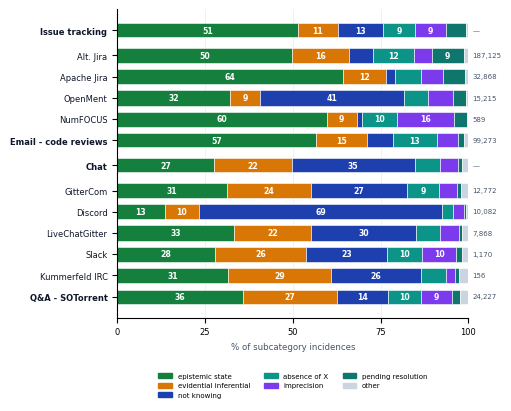

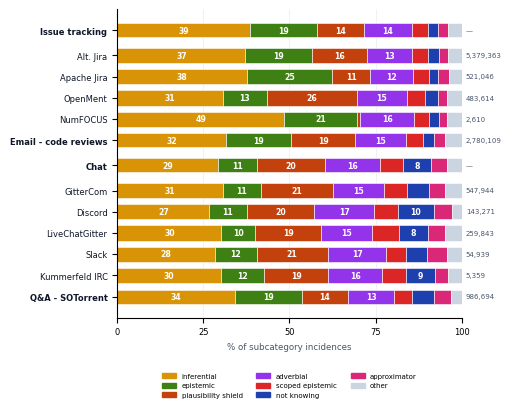

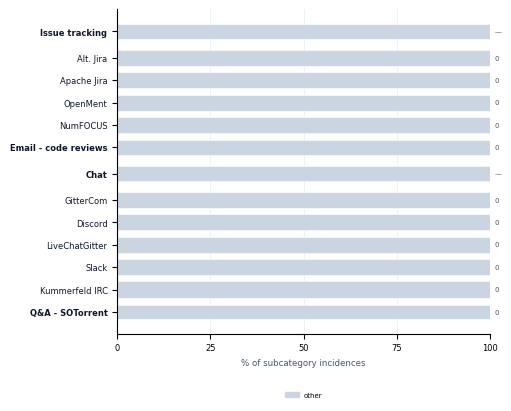

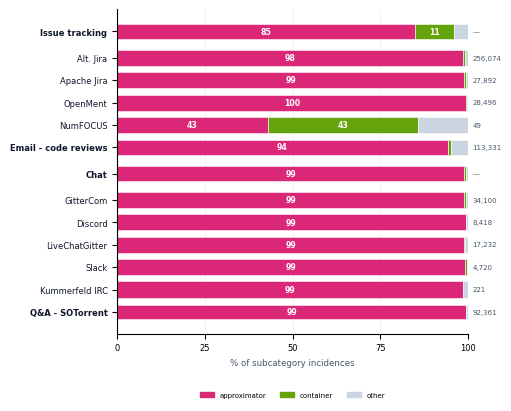

In [49]:
# ── Figure A — composition (dominance), one figure per layer ───────────────
# Each layer is exported as its own figure; rows = genre bar (equal-weight mean
# of its datasets) then each dataset, ordered as in Fig B. Segments ordered by
# reference share R desc, so the leftmost segment is comparable across every bar.
import matplotlib.patches as mpatches


def _kept_subcats(layer):
    order = R[R.layer == layer].sort_values("R", ascending=False)["subcategory"].tolist()
    pgen = P[P.layer == layer]
    kept = [s for s in order
            if pgen[pgen.subcategory == s].P.max() >= OTHER_SHARE_THRESH]
    return kept[:MAX_SEGMENTS]


def _row_specs():
    specs = []
    for g in GENRE_ORDER:
        sets = sorted(c[c.genre == g].dataset.unique(),
                      key=lambda d: -c[(c.dataset == d) & (c.layer == "lexical")].n_signals.sum())

        if g in ["qa","email"]:
            for d in sets:
                specs.append({"label":str(GENRE_LABEL[g]) + " - " + str(DATASET_LABEL_SHORT.get(d, d)), "kind": "genre",
                            "genre": g, "dataset": d})
            continue

        specs.append({"label": GENRE_LABEL[g], "kind": "genre", "genre": g, "dataset": None})
        for d in sets:
            specs.append({"label": DATASET_LABEL_SHORT.get(d, d), "kind": "dataset",
                          "genre": g, "dataset": d})
    return specs


def _shares(layer, kept, spec):
    if spec["dataset"] is not None:
        row = c[(c.layer == layer) & (c.dataset == spec["dataset"])]
        total = int(row.n_signals.sum())
        share = (row.set_index("subcategory").n_signals / total) if total else row.n_signals
        N = total
    else:
        share = P[(P.layer == layer) & (P.genre == spec["genre"])].set_index("subcategory").P
        N = None
    parts = [float(share.get(s, 0.0)) for s in kept]
    return parts, max(0.0, 1.0 - sum(parts)), N


row_specs = _row_specs()
for layer in LAYER_ORDER:
    fig, ax = plt.subplots(figsize=(5.0, 4.0), layout="constrained")
    kept = _kept_subcats(layer)
    ys, y = [], 0.0
    for spec in row_specs:
        ys.append(y)
        y += 1.18 if spec["kind"] == "genre" else 1.0
    for spec, yy in zip(row_specs, ys):
        parts, rest, N = _shares(layer, kept, spec)
        left = 0.0
        h = 0.66 if spec["kind"] == "genre" else 0.72
        for val, sub in zip(parts, kept):
            if val > 0:
                ax.barh(yy, val, left=left, height=h, color=subcat_color(sub),
                        edgecolor="white", linewidth=0.4)
                if val >= 0.08:
                    ax.text(left + val / 2, yy, f"{val * 100:.0f}", ha="center",
                            va="center", fontsize=5.6, color="white", fontweight="bold")
            left += val
        if rest > 1e-9:
            ax.barh(yy, rest, left=left, height=h, color=OTHER_COLOR,
                    edgecolor="white", linewidth=0.4)
        ax.text(1.012, yy, "—" if N is None else f"{N:,}",
                transform=ax.get_yaxis_transform(), ha="left", va="center",
                fontsize=5.0, color=GREY_TEXT)
    ax.set_yticks(ys)
    ax.set_yticklabels([s["label"] for s in row_specs], fontsize=6.0, color=INK)
    for tick, spec in zip(ax.get_yticklabels(), row_specs):
        if spec["kind"] == "genre":
            tick.set_fontweight("bold")
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_xticklabels(["0", "25", "50", "75", "100"], fontsize=6)
    #ax.set_title(LAYER_LABEL[layer], fontsize=7.4, fontweight="bold", loc="left", color=INK)
    ax.set_xlabel("% of subcategory incidences", fontsize=6.2, color=GREY_TEXT)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    ax.xaxis.grid(True, color=GRID, lw=0.4)
    ax.set_axisbelow(True)
    handles = [mpatches.Patch(color=subcat_color(s), label=s.replace("_", " ")) for s in kept]
    handles.append(mpatches.Patch(color=OTHER_COLOR, label="other"))
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.16),
              ncol=3, fontsize=5.0, frameon=False)
    _export_fig(fig, f"fig_genre_composition_{layer}")

plt.show()


Fig B rows shown: 21 (dropped 3 with R<0.01 and |E|<1)


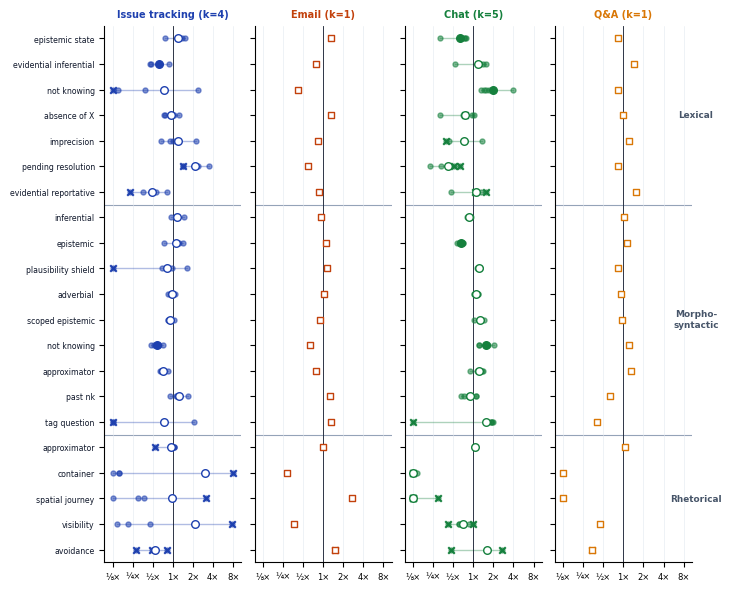

In [50]:
# ── Figure B — genre fingerprints (distinctiveness) ──────────────────────────
# One facet per genre; rows ordered by layer then reference share R (same order
# as Fig A's segments). Dots = datasets, line = dataset range, large marker =
# genre mean: filled = consistent driver, open = dataset-specific/weak, square =
# single-dataset genre (k=1, consistency undefined), × = low-count dataset cell.
# Rows are grouped by layer (the linguistic phenomenon); grey rules separate the
# groups and the phenomenon name is set on the far right, clear of the
# subcategory tick labels on the left.
rows = (R.assign(_lr=R.layer.map({l: i for i, l in enumerate(LAYER_ORDER)}))
          .sort_values(["_lr", "R"], ascending=[True, False]))
keep_rows = []
for r in rows.itertuples():
    strongest = ge[(ge.layer == r.layer) & (ge.subcategory == r.subcategory)].E.abs().max()
    if r.R >= ROW_DROP_R or (pd.notna(strongest) and strongest >= 1.0):
        keep_rows.append((r.layer, r.subcategory))
ypos = {k: i for i, k in enumerate(keep_rows)}
dropped = len(rows) - len(keep_rows)

# Consecutive rows sharing a layer form one phenomenon block [layer, start, end].
LAYER_RULE = "#94A3B8"
layer_groups = []
for i, (layer, _sub) in enumerate(keep_rows):
    if layer_groups and layer_groups[-1][0] == layer:
        layer_groups[-1][2] = i
    else:
        layer_groups.append([layer, i, i])

fig, axes = plt.subplots(1, 4, figsize=(7.2, 5.8), layout="constrained",
                         sharex=True, sharey=True)
for ax, g in zip(axes, GENRE_ORDER):
    ax.axvline(0, color=INK, lw=0.6)
    for _l, start, _e in layer_groups[1:]:
        ax.axhline(start - 0.5, color=LAYER_RULE, lw=0.8, zorder=0)
    for (layer, sub), k in ypos.items():
        dd = ds[(ds.genre == g) & (ds.layer == layer) & (ds.subcategory == sub)]
        gg = ge[(ge.genre == g) & (ge.layer == layer) & (ge.subcategory == sub)]
        if dd.empty:
            continue
        ee = dd.e.clip(-X_CLIP, X_CLIP)
        if len(ee) >= 2:
            ax.plot([ee.min(), ee.max()], [k, k], color=GENRE_COLOR[g],
                    lw=1.0, alpha=0.35, zorder=1)
        ax.scatter(ee, [k] * len(ee), s=13, color=GENRE_COLOR[g], alpha=0.55, zorder=2)
        for e_low in dd.loc[dd.low_count, "e"].clip(-X_CLIP, X_CLIP):
            ax.scatter([e_low], [k], marker="x", s=22, color=GENRE_COLOR[g], zorder=3)
        if not gg.empty:
            E = float(np.clip(gg.E.iloc[0], -X_CLIP, X_CLIP))
            if bool(gg.single_dataset.iloc[0]):
                ax.scatter([E], [k], marker="s", s=24, facecolor="white",
                           edgecolor=GENRE_COLOR[g], linewidth=1.0, zorder=4)
            elif bool(gg.consistent_driver.iloc[0]):
                ax.scatter([E], [k], marker="o", s=30, color=GENRE_COLOR[g], zorder=4)
            else:
                ax.scatter([E], [k], marker="o", s=30, facecolor="white",
                           edgecolor=GENRE_COLOR[g], linewidth=1.0, zorder=4)
    ax.set_title(f"{GENRE_LABEL[g]} (k={GENRE_K.get(g, 0)})", fontsize=7.0,
                 fontweight="bold", color=GENRE_COLOR[g])
    ax.set_ylim(len(keep_rows) - 0.5, -0.5)
    ax.set_xlim(-3.4, 3.4)
    ax.set_xticks([-3, -2, -1, 0, 1, 2, 3])
    ax.set_xticklabels(["⅛×", "¼×", "½×", "1×", "2×", "4×", "8×"], fontsize=6)
    ax.xaxis.grid(True, color=GRID, lw=0.4)
    ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
axes[0].set_yticks(range(len(keep_rows)))
axes[0].set_yticklabels([sub.replace("_", " ") for _l, sub in keep_rows], fontsize=5.6, color=INK)
# Phenomenon names on the right edge of the last facet (one per layer block).
right = axes[-1]
for layer, start, end in layer_groups:
    if layer in ["morpho_syntactic"]:
        right.text(1.03, (start + end) / 2, "Morpho-\nsyntactic",
                transform=right.get_yaxis_transform(), ha="center", va="center",
                fontsize=6.4, fontweight="bold", color=GREY_TEXT)
        continue
    right.text(1.03, (start + end) / 2, LAYER_LABEL[layer],
               transform=right.get_yaxis_transform(), ha="center", va="center",
               fontsize=6.4, fontweight="bold", color=GREY_TEXT)
#fig.suptitle("Fig B — genre fingerprints (log₂ share vs. reference composition)",
#            fontsize=8.0, fontweight="bold", color=INK)
print(f"Fig B rows shown: {len(keep_rows)} (dropped {dropped} with R<{ROW_DROP_R} and |E|<1)")
_export_fig(fig, "fig_genre_fingerprints")
plt.show()


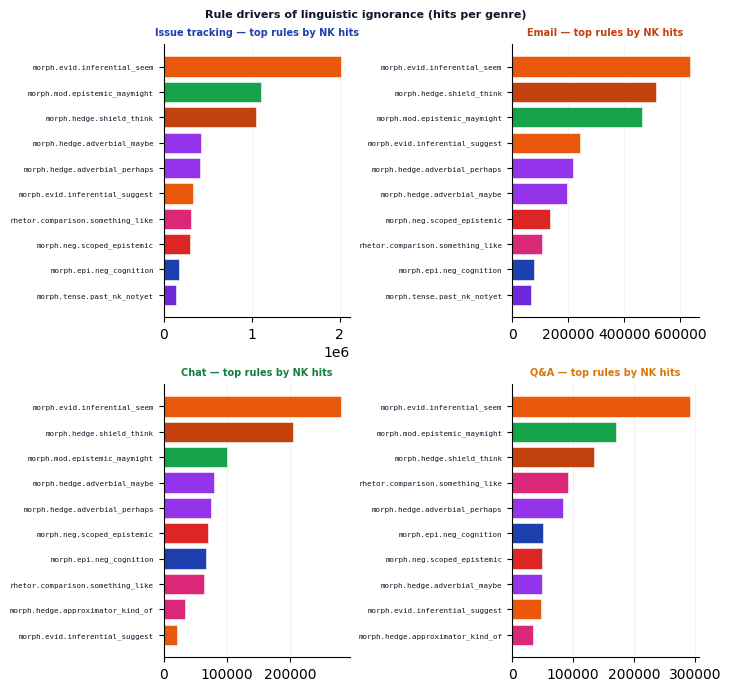

wrote /Users/giulianowietig/PycharmProjects/Graph-NK/notebooks/genre_rule_drivers.csv (192 rows)


,rule_id,layer,subcategory,n_signals,share_in_genre
176,morph.evid.inferential_seem,morpho_syntactic,inferential,2015889,0.290686
172,morph.mod.epistemic_maymight,morpho_syntactic,epistemic,1104098,0.159208
181,morph.hedge.shield_think,morpho_syntactic,plausibility_shield,1043160,0.150421
166,morph.hedge.adverbial_maybe,morpho_syntactic,adverbial,424831,0.061259
167,morph.hedge.adverbial_perhaps,morpho_syntactic,adverbial,416738,0.060093
177,morph.evid.inferential_suggest,morpho_syntactic,inferential,334218,0.048193
184,rhetor.comparison.something_like,rhetorical,approximator,308134,0.044432
182,morph.neg.scoped_epistemic,morpho_syntactic,scoped_epistemic,295433,0.042601
178,morph.epi.neg_cognition,morpho_syntactic,not_knowing,175896,0.025364
180,morph.tense.past_nk_notyet,morpho_syntactic,past_nk,137584,0.019839


In [18]:
# ── RQ3.7.3 — which rule_ids drive each genre (rule level) ──────────────────
# The rule rows carry the traceable carriers of each subcategory; this is the
# 'which rule_ids drive ignorance' view, complementary to Fig A's subcategory
# composition.
rule = comp[comp.granularity == "rule"].copy()
drivers = (rule.groupby(["genre", "layer", "subcategory", "rule_id"], as_index=False)
               .n_signals.sum())
drivers = drivers[drivers.n_signals > 0].copy()
drivers["share_in_genre"] = (drivers.n_signals
                             / drivers.groupby("genre").n_signals.transform("sum"))
drivers.sort_values(["genre", "n_signals"], ascending=[True, False]).to_csv(
    ROOT / "notebooks" / "genre_rule_drivers.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(7.2, 6.8), layout="constrained")
for ax, g in zip(axes.ravel(), GENRE_ORDER):
    top = drivers[drivers.genre == g].nlargest(10, "n_signals").iloc[::-1]
    ax.barh(range(len(top)), top.n_signals,
            color=[subcat_color(s) for s in top.subcategory], edgecolor="white", lw=0.4)
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels([r.rule_id.replace("lex.", "") for r in top.itertuples()],
                       fontsize=5.4, family="monospace", color=INK)
    ax.set_title(f"{GENRE_LABEL[g]} — top rules by NK hits", fontsize=7.0,
                 fontweight="bold", color=GENRE_COLOR[g])
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    ax.xaxis.grid(True, color=GRID, lw=0.4)
    ax.set_axisbelow(True)
fig.suptitle("Rule drivers of linguistic ignorance (hits per genre)",
             fontsize=8.0, fontweight="bold", color=INK)
#_export_fig(fig, "fig_genre_rule_drivers")
plt.show()
print(f"wrote {ROOT / 'notebooks' / 'genre_rule_drivers.csv'} ({len(drivers)} rows)")
display(drivers[drivers.genre == GENRE_ORDER[0]].nlargest(15, "n_signals")
               [["rule_id", "layer", "subcategory", "n_signals", "share_in_genre"]])


In [43]:
# ── RQ3.7.4 — robustness variants and the claim-stability diff ───────────────
# Only claims stable across variants belong in the paper text. Variants:
#   _units      count basis = distinct units instead of hits (needs --with-units)
#   _pooled     genre composition pooled by counts instead of equal dataset weight
#   _activeonly active-only rule set (needs genre_composition_counts_active.csv)


def _effects(comp_df):
    cc, _pp, rr = composition_shares(comp_df)
    _dd, gg = distinctiveness(cc, rr, alpha=ALPHA, min_count=MIN_COUNT,
                              consistency=CONSISTENCY)
    return gg.set_index(["genre", "layer", "subcategory"])


variants = {"primary": ge.set_index(["genre", "layer", "subcategory"])}

_subc = comp[comp.granularity == "subcategory"]
if "n_units" in comp.columns and _subc.n_units.notna().any():
    cu = _subc.copy()
    cu["n_signals"] = cu["n_units"]          # swap count basis
    variants["_units"] = _effects(cu)

_pool = comp[comp.granularity == "subcategory"].copy()
_pool["dataset"] = _pool.genre + ":pooled"
_pool["N"] = _pool.groupby(["dataset", "layer"]).n_signals.transform("sum")
_pp = _pool.groupby(["genre", "layer", "subcategory"], as_index=False).n_signals.sum()
_pp["P"] = _pp.n_signals / _pp.groupby(["genre", "layer"]).n_signals.transform("sum")
_rp = _pp.groupby(["layer", "subcategory"], as_index=False).P.mean().rename(columns={"P": "R"})
cp = _pp.rename(columns={"P": "p"})
cp["dataset"] = cp.genre + ":pooled"
cp["N"] = cp.groupby(["dataset", "layer"]).n_signals.transform("sum")
cp["p"] = cp.n_signals / cp.N
variants["_pooled"] = distinctiveness(cp, _rp, alpha=ALPHA, min_count=MIN_COUNT,
                                      consistency=CONSISTENCY)[1].set_index(
    ["genre", "layer", "subcategory"])

if COMP_CSV_ACTIVE.exists():
    variants["_activeonly"] = _effects(pd.read_csv(COMP_CSV_ACTIVE))
else:
    print("(_activeonly variant skipped — run with --ruleset active to enable)")

common = variants["primary"].index
for v in variants.values():
    common = common.intersection(v.index)
diff = pd.DataFrame(index=common)
for name, v in variants.items():
    diff[f"sign_{name}"] = np.sign(v.loc[common, "E"]).astype(int)
    diff[f"driver_{name}"] = v.loc[common, "consistent_driver"].astype(bool)
diff["sign_changed"] = diff[[c for c in diff if c.startswith("sign_")]].nunique(axis=1) > 1
diff["driver_changed"] = diff[[c for c in diff if c.startswith("driver_")]].nunique(axis=1) > 1
changed = diff[diff.sign_changed | diff.driver_changed].reset_index()
print(f"Variant-sensitive (genre, layer, subcategory) cells: {len(changed)} of {len(diff)} "
      f"across {list(variants)}")
display(changed.head(40))


(_activeonly variant skipped — run with --ruleset active to enable)
Variant-sensitive (genre, layer, subcategory) cells: 31 of 156 across ['primary', '_units', '_pooled']


,genre,layer,subcategory,sign_primary,driver_primary,sign__units,driver__units,sign__pooled,driver__pooled,sign_changed,driver_changed
0,chat,lexical,epistemic_state,-1,True,-1,False,-1,False,False,True
1,chat,lexical,evidential_reportative,1,False,1,False,-1,False,True,False
2,chat,lexical,not_knowing,1,True,1,True,1,False,False,True
3,chat,morpho_syntactic,attribution_shield,-1,False,-1,False,1,False,True,False
4,chat,morpho_syntactic,deontic,-1,True,-1,True,-1,False,False,True
5,chat,morpho_syntactic,not_knowing,1,True,1,False,1,False,False,True
6,chat,morpho_syntactic,past_nk,-1,False,-1,False,1,False,True,False
7,chat,morpho_syntactic,underspecified,-1,False,1,False,-1,False,True,False
8,chat,word_formation,less_suffix,1,True,1,True,1,False,False,True
9,chat,word_formation,un_prefix,-1,False,1,False,-1,False,True,False


---
# RQ4 · Do the borrowed taxonomies transfer to SE artefacts, and where do they fail?

*Restructured in v0.2. Replaces the single RQ4 of v0.1 in full.*

| sub-RQ | question | evidence base | runs without a corpus? |
|---|---|---|---|
| **RQ4a** | How much can the taxonomies discriminate *on their own terms*? | codebook + crosswalk + audit | **yes** |
| **RQ4b** | Which categories are populated by SE non-knowledge? | multi-fit coded sample | no |
| **RQ4c** | Do the predicted collapses manifest in coder behaviour? | two-coder agreement | no |
| **RQ4d** | What resists every category, and is multi-actor NK the gap? | primary-code sample + rationales | no |

**What v0.1 did wrong, and what replaces it.** v0.1 clustered units on 15 `layer.category`
features and read cluster membership as taxonomic fit; three failures compounded (cohort
query silently excluded the marker−/classifier+ population; the features aggregated away
the SE-native subcategories the RQ exists to find; a small cluster was reported as "the
residual", producing a 99.9%-coverage artefact). In v0.2, **clustering is demoted to
sampling-frame construction only**; the residual is defined and counted from hand-coded
units. 02b keeps this design, with the sampling frame drawn from the curated corpora.

## RQ4a · Instrument-level discriminability *(no corpus required)*

**Question.** Across Roberts (2013), Smithson (1989/1993), Gross (2010) and Wehling (2024):
which categories are mutually non-discriminating, which share labels while denoting
differently-scoped concepts, and how evenly is each taxonomy evidenced in its own primary
literature?

**Why this is Layer 0.** It makes no empirical claim about SE, so it cannot be attacked on
sampling, annotation, or corpus-composition grounds. It is the cheapest defensible
contribution in the paper and it *frames* RQ4b–d: a category that no coder in any domain
could apply discriminatingly is not evidence about software engineering when it comes back
empty.

In [ ]:
# RQ4a.1 — The instrument, inventoried. Everything derived from the codebook YAML.
print("Categories per taxonomy:")
display(CATS.groupby("taxonomy").agg(
    categories=("type_id", "size"),
    with_vagueness=("has_vagueness", "sum"),
    access=("access", "first"),
))

print("\nWehling dimensions (orthogonal axes — NOT categories):")
display(DIMS[["dimension_id", "name", "permitted_values", "confidence"]])


In [ ]:
# RQ4a.2 — Relation counts and the NONE_POSSIBLE set.
# `near_neighbours` entries whose distinguishing_test begins NONE_POSSIBLE are
# pairs the SOURCE LITERATURE cannot tell apart. These are the RQ4c predictions.
RELS["scope"] = np.where(RELS.from_tax == RELS.to_tax, "intra_taxonomy", "cross_taxonomy")

# Many relations are declared from BOTH sides (A lists B as a neighbour and B
# lists A). Counting raw rows double-counts every reciprocal pair, so the
# reported figures are over UNDIRECTED pairs. `none_possible` is OR-ed across
# the two directions: if either side says no test exists, none exists.
RELS["pair"] = [frozenset((r["from"], r["to"])) for _, r in RELS.iterrows()]
PAIRS = (RELS.groupby("pair")
             .agg(relation=("relation", "first"), scope=("scope", "first"),
                  none_possible=("none_possible", "max"),
                  declared_both_ways=("relation", "size"))
             .reset_index())
PAIRS[["a", "b"]] = pd.DataFrame([sorted(p) for p in PAIRS.pair], index=PAIRS.index)
print(f"{len(RELS)} declarations → {len(PAIRS)} undirected pairs "
      f"({int((PAIRS.declared_both_ways > 1).sum())} declared reciprocally)\n")

summary = PAIRS.groupby(["scope", "relation"]).size().unstack(fill_value=0)
print("Relation type × scope (undirected pairs):")
display(summary)

np_rels = PAIRS[PAIRS.none_possible].rename(columns={"a": "from", "b": "to"})
n_cross = int((PAIRS.scope == "cross_taxonomy").sum())
n_cross_np = int(((PAIRS.scope == "cross_taxonomy") & PAIRS.none_possible).sum())
if n_cross:
    print(f"\nCross-taxonomy pairs: {n_cross}, of which NONE_POSSIBLE: {n_cross_np} "
          f"({n_cross_np / n_cross:.0%})")
print("\nPairs with NO distinguishing test — the RQ4c prediction set:")
display(np_rels[["from", "to", "relation", "scope"]].reset_index(drop=True))

# The label collision gets its own callout: same word, different-sized concepts,
# inside the borrowed literature.
conflicts = PAIRS[PAIRS.relation == "conflicting"].rename(columns={"a": "from", "b": "to"})
if len(conflicts):
    print("\n⚠️ CONFLICTING pairs (same/overlapping label, different referent):")
    display(conflicts[["from", "to", "scope"]].reset_index(drop=True))
    print("Analysis code must key on full type_id, never on the English name.")


In [ ]:
# RQ4a.3 — THE confound table. Every coverage claim in RQ4b must be read against
# this: a category that comes back empty may be telling you about SE discourse,
# or it may be telling you that its definition was reconstructed from secondary
# paraphrase and sits last in the decision procedure.
#
# Priority order is from CODING_MANUAL.md §3 — fixed on evidentiary grounds
# before corpus contact, NOT on fit to SE material.
TAXONOMY_PRIORITY = {"roberts_2013": 1, "wehling_2024": 2,
                     "smithson_1989": 3, "gross_2010": 4}

conf_order = ["high", "medium-high", "medium", "low"]
confound = (CATS.assign(priority=CATS.taxonomy.map(TAXONOMY_PRIORITY))
                .groupby(["taxonomy", "priority", "access", "confidence"])
                .size().rename("categories").reset_index())
confound["confidence"] = pd.Categorical(confound["confidence"], conf_order, ordered=True)
display(confound.sort_values(["priority", "confidence"]))

low_and_last = CATS[(CATS.confidence == "low") &
                    (CATS.taxonomy.map(TAXONOMY_PRIORITY) >= 3)]
print(f"\n{len(low_and_last)} categories are BOTH low-confidence AND low-priority:")
print("  ", sorted(low_and_last.type_id.tolist()))
print("A zero count for any of these is uninterpretable as evidence about SE.")
print("RQ4b flags them automatically.")
UNINTERPRETABLE_IF_EMPTY = set(low_and_last.type_id)


In [ ]:
# RQ4a.4 — Export the RQ4a table for the paper. This is publishable today,
# independently of every corpus decision still outstanding.
rq4a_out = Path("02b_rq4a_instrument_discriminability.csv")
(PAIRS.assign(none_possible=PAIRS.none_possible.astype(int))
      .drop(columns=["pair"]).to_csv(rq4a_out, index=False))
print(f"→ {rq4a_out}")

cat_out = Path("02b_rq4a_category_confidence.csv")
CATS.assign(priority=CATS.taxonomy.map(TAXONOMY_PRIORITY)).to_csv(cat_out, index=False)
print(f"→ {cat_out}")
print("\nRQ4a is complete and does not depend on anything below.")


---
## RQ4 · Sampling frame construction
*Everything in this subsection exists to draw a defensible sample for RQ4b–d. None of it is
reported as a finding.*

**Three deliberate changes from v0.1 (kept from v0.2):**
1. **Cohort query fixed** — both conditions sit in `EXISTS` subqueries so neither constrains
   the feature join.
2. **Binary features at subcategory level** — per-unit counts make the distance a proxy for
   unit length; binarising removes that.
3. **Near-universal features dropped from the clustering space.**

**02b change.** The cohort is restricted to the curated corpora via the parent artefact's
`corpus_id`, and `corpus` is carried as metadata so the sample can be stratified across the
12 datasets.

In [ ]:
# RQ4.S1 — Cohort + binary subcategory feature matrix.
# Cohort: units with ≥1 NK signal OR a positive classifier verdict, restricted to
# the curated corpora. Classifier status is carried as METADATA for stratification
# — it is never a clustering feature (that would rebuild the v0.1 circularity).
rq4_long = q(f"""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
  AND (
    EXISTS {{ MATCH (u)-[:HAS_SIGNAL]->(s:Signal) WHERE {NK_SIGNAL_PREDICATE} }}
    OR EXISTS {{ MATCH (u)-[:CLASSIFIED_AS]->(v:ClassifierVerdict) WHERE v.label = 1 }}
  )
WITH u, p,
     CASE WHEN EXISTS {{
       MATCH (u)-[:CLASSIFIED_AS]->(v:ClassifierVerdict) WHERE v.label = 1
     }} THEN 1 ELSE 0 END AS clf_pos
OPTIONAL MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
WHERE {NK_SIGNAL_PREDICATE}
RETURN u.id AS unit,
       coalesce(p.corpus_id, '') AS corpus,
       clf_pos,
       coalesce(s.layer + '.' + coalesce(s.subcategory, s.category), '_no_signal') AS feature,
       count(s) AS n
""", corpora=IN_SCOPE_CORPORA, non_nk=NON_NK_SUBCATS, rule_version=V, active_rules=ACTIVE_RULE_IDS)

COHORT = (rq4_long[["unit", "clf_pos"]].drop_duplicates().set_index("unit")["clf_pos"])
print(f"Cohort: {len(COHORT):,} units "
      f"({int((COHORT == 1).sum()):,} classifier-positive)")
print("Expected = |marker+ ∪ clf+| from RQ5.1. If this equals the marker+/clf+ cell")
print("alone, the OPTIONAL-MATCH fix did not take.")

# Long → sparse binary. Built directly from categorical codes rather than
# pivot_table: a dense frame would be ~570 MB for the full corpus.
from scipy import sparse

feat_long = rq4_long[rq4_long.feature != "_no_signal"].copy()
u_cat = pd.Categorical(feat_long["unit"], categories=COHORT.index)
f_cat = pd.Categorical(feat_long["feature"])
B = sparse.csr_matrix(
    (np.ones(len(feat_long), dtype=np.int8), (u_cat.codes, f_cat.codes)),
    shape=(len(COHORT), len(f_cat.categories)),
)
B.data[:] = 1                      # binarise: presence, not count
FEATURES = list(f_cat.categories)
print(f"Binary feature matrix: {B.shape[0]:,} units × {B.shape[1]} subcategory features")
print(f"Density: {B.nnz / (B.shape[0] * B.shape[1]):.3%}")


In [ ]:
# RQ4.S2 — Feature prevalence, and the drop list for the clustering space.
prev = pd.Series(np.asarray(B.sum(axis=0)).ravel(), index=FEATURES, name="units")
prev_df = (prev.to_frame()
               .assign(prevalence=lambda d: d.units / B.shape[0])
               .sort_values("units", ascending=False))

UBIQUITY_THRESHOLD = 0.25          # present in >25% of the cohort
DROPPED = prev_df.index[prev_df.prevalence > UBIQUITY_THRESHOLD].tolist()
print(f"Dropped from the clustering space (prevalence > {UBIQUITY_THRESHOLD:.0%}):")
for f in DROPPED:
    print(f"  {f:<45s} {prev_df.loc[f, 'prevalence']:.1%}")
print("\nThese remain in the corpus and in every RQ1–RQ3 count — they are excluded")
print("only from the profile space, because a feature carried by a quarter of the")
print("cohort cannot discriminate between profiles.")
display(prev_df.head(30))


In [ ]:
# RQ4.S3 — Marker co-occurrence graph + communities.
#
# This clusters MARKERS, not units — closer to "which taxonomic categories are
# populated" than unit clustering ever was, and immune to the unit-length
# confound because NPMI is computed over presence.
keep = [i for i, f in enumerate(FEATURES) if f not in DROPPED]
Bk = B[:, keep].astype(np.float64)
names = [FEATURES[i] for i in keep]

N = Bk.shape[0]
co = np.asarray((Bk.T @ Bk).todense())        # co-occurrence counts; diag = marginals
marg = np.diag(co).copy()
with np.errstate(divide="ignore", invalid="ignore"):
    p_ij = co / N
    p_i = marg / N
    pmi = np.log(p_ij / np.outer(p_i, p_i))
    npmi = pmi / -np.log(p_ij)
npmi[~np.isfinite(npmi)] = 0.0
np.fill_diagonal(npmi, 0.0)

NPMI_THRESHOLD = 0.10
MIN_CO = 30                                    # ignore pairs seen too rarely to trust
edges = [(names[i], names[j], float(npmi[i, j]))
         for i in range(len(names)) for j in range(i + 1, len(names))
         if npmi[i, j] > NPMI_THRESHOLD and co[i, j] >= MIN_CO]
print(f"{len(names)} markers, {len(edges)} edges "
      f"(NPMI > {NPMI_THRESHOLD}, co-occurrence ≥ {MIN_CO})")

# Leiden if available; NetworkX greedy modularity otherwise. Both are reported
# with their modularity so the choice is visible rather than silent.
try:
    import igraph as ig
    import leidenalg
    g = ig.Graph()
    g.add_vertices(names)
    g.add_edges([(a, b) for a, b, _ in edges])
    g.es["weight"] = [w for _, _, w in edges]
    part = leidenalg.find_partition(g, leidenalg.ModularityVertexPartition,
                                    weights="weight", seed=42)
    COMMUNITY = {names[v]: c for c, vs in enumerate(part) for v in vs}
    algo, modularity = "leiden", part.modularity
except ImportError:
    import networkx as nx
    from networkx.algorithms.community import greedy_modularity_communities, modularity as nx_mod
    G = nx.Graph()
    G.add_nodes_from(names)
    G.add_weighted_edges_from(edges)
    comms = list(greedy_modularity_communities(G, weight="weight"))
    COMMUNITY = {n: c for c, s in enumerate(comms) for n in s}
    algo, modularity = "networkx-greedy (leidenalg not installed)", nx_mod(G, comms, weight="weight")

comm_df = (pd.DataFrame({"marker": names})
             .assign(community=lambda d: d.marker.map(COMMUNITY),
                     units=lambda d: d.marker.map(prev))
             .sort_values(["community", "units"], ascending=[True, False]))
print(f"Algorithm: {algo} — modularity {modularity:.3f}, "
      f"{comm_df.community.nunique()} communities")
display(comm_df.groupby("community").agg(
    markers=("marker", "size"),
    members=("marker", lambda s: ", ".join(s.head(6))),
))
comm_df.to_csv("02b_rq4_marker_communities.csv", index=False)
print("→ 02b_rq4_marker_communities.csv")


In [ ]:
# RQ4.S4 — Strata. Maximum-variation purposive design (Patton; Baltes & Ralph 2022):
# the goal is to see rare profiles, NOT to mirror corpus proportions, because a
# proportional sample of 400 would contain ~0 SE-native units and RQ4d would have
# nothing to characterise.
#
# Each unit's stratum is its RAREST present marker subcategory — inverse-frequency
# assignment, so units carrying a rare SE-native marker are strata of their own.
# The marker-negative/classifier-positive population gets a dedicated stratum and
# the largest single allocation: it is RQ5b's population.
rank = {f: r for r, f in enumerate(prev_df.index)}    # 0 = most common
rarest = np.full(B.shape[0], -1, dtype=np.int64)
Bc = B.tocoo()
best = np.full(B.shape[0], 10**9, dtype=np.int64)
for u_i, f_i in zip(Bc.row, Bc.col):
    r = rank[FEATURES[f_i]]
    if r < best[u_i]:
        best[u_i] = r
        rarest[u_i] = f_i

frame = pd.DataFrame({
    "unit": COHORT.index,
    "clf_pos": COHORT.values,
    "corpus": rq4_long.drop_duplicates("unit")[["unit", "corpus"]].set_index("unit")
                      .reindex(COHORT.index).corpus.fillna("").values,
    "rarest_marker": [FEATURES[i] if i >= 0 else None for i in rarest],
})
frame["stratum"] = np.where(
    frame.rarest_marker.isna(),
    "MARKER_NEG_CLF_POS",
    frame.rarest_marker.fillna("") + "|clf" + frame.clf_pos.astype(str),
)
frame["community"] = frame.rarest_marker.map(COMMUNITY)

strata_sizes = frame.stratum.value_counts()
print(f"{len(strata_sizes)} strata. Largest 10:")
display(strata_sizes.head(10))
print(f"\nMARKER_NEG_CLF_POS stratum: "
      f"{int(strata_sizes.get('MARKER_NEG_CLF_POS', 0)):,} units")


In [ ]:
# RQ4.S5 — Draw the coding sample.
#
# Size: RESIDUAL rate is the headline number, so the sample is sized on it. At
# ~400 CODABLE units a Wilson interval is roughly ±5pp. P6 predicts NOT_NK will
# be common, so the draw is inflated by the expected NOT_NK share.
TARGET_CODABLE      = 400
EXPECTED_CODABLE_RATE = 0.55      # pilot estimate — REVISE after first 50 units
TARGET_DRAW         = int(TARGET_CODABLE / EXPECTED_CODABLE_RATE)
OVERLAP_N           = 200         # double-coded, for RQ4c agreement
MNCP_ALLOCATION     = 0.25        # share of the draw reserved for marker−/clf+
CONTEXT_SUBSAMPLE   = 150         # units shown with parent chain, for P4 (RQ4d)
SEED                = 20240817

rng = np.random.default_rng(SEED)

mncp = frame[frame.stratum == "MARKER_NEG_CLF_POS"]
rest = frame[frame.stratum != "MARKER_NEG_CLF_POS"]

n_mncp = min(len(mncp), int(TARGET_DRAW * MNCP_ALLOCATION))
picks = [mncp.sample(n=n_mncp, random_state=SEED)]

# Remaining budget spread across strata with a sqrt-size allocation: rare strata
# stay visible, common strata do not swamp the sample.
budget = TARGET_DRAW - n_mncp
sizes = rest.stratum.value_counts()
w = np.sqrt(sizes)
alloc = (w / w.sum() * budget).round().astype(int).clip(lower=1)
for stratum, k in alloc.items():
    pool = rest[rest.stratum == stratum]
    picks.append(pool.sample(n=min(k, len(pool)), random_state=SEED))

sample = pd.concat(picks, ignore_index=True).drop_duplicates(subset="unit")
sample = sample.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
sample["coding_id"] = [f"C{i:05d}" for i in range(len(sample))]
sample["in_overlap"] = sample.index < OVERLAP_N
sample["with_context"] = (sample.index >= OVERLAP_N) & \
                         (sample.index < OVERLAP_N + CONTEXT_SUBSAMPLE)

print(f"Drawn {len(sample):,} units across {sample.stratum.nunique()} strata")
print(f"  marker−/clf+ : {int((sample.stratum == 'MARKER_NEG_CLF_POS').sum())}")
print(f"  double-coded : {int(sample.in_overlap.sum())} (RQ4c)")
print(f"  with context : {int(sample.with_context.sum())} (P4 test, RQ4d)")
display(sample.stratum.value_counts().head(12))


In [ ]:
# RQ4.S6 — Blinded export.
#
# v0.1 wrote the cluster id into the same CSV the coder reads, alongside empty
# `roberts` / `smithson` columns. A coder who can see a cluster id codes toward
# it, and the coding stops being independent evidence. Here: text only, shuffled,
# no stratum, no marker labels, no cluster, no classifier verdict. Stratum
# membership lives in a separate key file that only the analyst holds.
texts = q("""
UNWIND $ids AS uid
MATCH (u:TextUnit {id: uid})
RETURN u.id AS unit, left(u.text, 1200) AS text
""", ids=sample["unit"].tolist())

# Parent-chain context for the P4 subsample. CODING_MANUAL §2 fixes the unit as
# a self-contained span, but P4 predicts DISTRIBUTED, multi-actor non-knowledge
# negotiated ACROSS turns — untestable if the coder never sees a thread. These
# units get preceding turns of the same parent artefact as read-only context.
ctx_ids = sample.loc[sample.with_context, "unit"].tolist()
context = q("""
UNWIND $ids AS uid
MATCH (u:TextUnit {id: uid})<-[:HAS_TEXT]-(p)-[:HAS_TEXT]->(prev:TextUnit)
WHERE prev.position < u.position
WITH uid, prev ORDER BY prev.position
RETURN uid AS unit,
       reduce(acc = '', t IN collect(left(prev.text, 300))[..4] |
              acc + '--- earlier turn ---\n' + t + '\n') AS context
""", ids=ctx_ids) if ctx_ids else pd.DataFrame(columns=["unit", "context"])

coder_df = (sample[["coding_id", "unit", "with_context"]]
            .merge(texts, on="unit", how="left")
            .merge(context, on="unit", how="left"))
coder_df["context"] = coder_df["context"].fillna("")

# Columns the coder fills. These match CODING_MANUAL.md's actual outputs.
BLANKS = {
    "primary_code": "",          # one of VALID_PRIMARY_CODES
    "multi_fit_candidates": "",  # ';'-separated type_ids — MANDATORY (RQ4b)
    "wehling_knowledge": "",     # scored on EVERY codable unit (RQ4b)
    "wehling_intentionality": "",
    "wehling_durability": "",
    "residual_but_for": "",      # type_id, if a catch-all was assigned (RQ4d)
    "rationale": "",             # MANDATORY for RESIDUAL
    "coder_id": "",
}

for coder in ["coderA", "coderB"]:
    subset = coder_df if coder == "coderA" else \
        coder_df[coder_df.coding_id.isin(sample.loc[sample.in_overlap, "coding_id"])]
    (subset.drop(columns=["unit"])          # ← the blind: no graph id in the coder file
           .assign(**BLANKS)
           .to_csv(f"02b_rq4_coding_{coder}.csv", index=False))
    print(f"→ 02b_rq4_coding_{coder}.csv ({len(subset)} rows)")

sample.to_csv("02b_rq4_sample_key.csv", index=False)   # analyst-only
print("→ 02b_rq4_sample_key.csv  (ANALYST ONLY — do not give this to coders)")


---
## RQ4b · Which categories are populated?

**Question.** Under the pre-registered instrument, which of the 28 categories and 3 Wehling
dimensions receive instances, and which receive none?

**Binding methodological requirement.** Coverage is computed from the **multi-fit pass**,
not the primary code. Two further corrections: Wehling's dimensions are scored on **every**
codable unit (they are orthogonal axes, not competitors), and Smithson coverage is
**hierarchy-aware** (a unit coded `smithson.absence` also populates `incompleteness` and
`error`).

**Empty cells are reported as rule-of-three upper bounds, never as "0"**, and always
alongside the category's confidence and access level from RQ4a.3.

In [ ]:
# RQ4b.1 — Ingest coded CSVs, validate every code against the codebook.
# Fails loudly on unknown codes: a typo'd type_id that silently becomes a new
# category would corrupt the coverage table in a way no downstream check catches.
def load_coding(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, dtype=str).fillna("")
    df = df[df.primary_code.str.strip() != ""]
    if df.empty:
        return df

    bad = set(df.primary_code) - VALID_PRIMARY_CODES
    assert not bad, f"{path.name}: unknown primary_code(s): {sorted(bad)}"

    multi = (df.multi_fit_candidates.str.split(";")
               .apply(lambda xs: [x.strip() for x in xs if x.strip()]))
    bad_multi = {c for xs in multi for c in xs} - CATEGORY_IDS
    assert not bad_multi, f"{path.name}: unknown multi_fit code(s): {sorted(bad_multi)}"
    df["multi_fit"] = multi

    for col, dim in [("wehling_knowledge", "wehling.knowledge_of_nonknowledge"),
                     ("wehling_intentionality", "wehling.intentionality"),
                     ("wehling_durability", "wehling.temporal_durability")]:
        vals = set(df[col]) - {""} - DIMENSION_VALUES[dim]
        assert not vals, f"{path.name}: invalid {col} value(s): {sorted(vals)}"

    # CODING_MANUAL §5.4: a RESIDUAL with no rationale is not a valid output.
    missing = df[(df.primary_code == "RESIDUAL") & (df.rationale.str.strip() == "")]
    if len(missing):
        print(f"⚠️ {path.name}: {len(missing)} RESIDUAL codes with no rationale — "
              f"incomplete, send back to the coder.")
    return df


key = pd.read_csv("02b_rq4_sample_key.csv")
CODINGS = {}
for coder in ["coderA", "coderB"]:
    p = Path(f"02b_rq4_coding_{coder}.csv")
    if p.exists():
        d = load_coding(p)
        if len(d):
            CODINGS[coder] = d.merge(key[["coding_id", "unit", "stratum", "clf_pos", "corpus"]],
                                     on="coding_id", how="left")
            print(f"{coder}: {len(d)} coded units")

if not CODINGS:
    print("No coded units yet. RQ4b–d run after coding; RQ4a above is complete.")
else:
    PRIMARY = CODINGS.get("coderA", next(iter(CODINGS.values())))
    CODABLE = PRIMARY[~PRIMARY.primary_code.isin(["NOT_NK", "UNCODABLE"])]
    print(f"\nPrimary coder: {len(PRIMARY)} coded, {len(CODABLE)} codable "
          f"({len(CODABLE)/len(PRIMARY):.0%})")
    print("P6 predicted NOT_NK common, UNCODABLE rare:")
    display(PRIMARY.primary_code.isin(["NOT_NK", "UNCODABLE"]).groupby(
        PRIMARY.primary_code.where(PRIMARY.primary_code.isin(["NOT_NK", "UNCODABLE"]),
                                   "codable")).size())


In [ ]:
# RQ4b.2 — Coverage from the MULTI-FIT pass, hierarchy-expanded.
if CODINGS:
    hits = {}
    for row in CODABLE.itertuples():
        applied = set(row.multi_fit)
        if row.primary_code in CATEGORY_IDS:
            applied.add(row.primary_code)
        expanded = set(applied)
        for c in applied:
            expanded.update(ancestors_of(c))      # Smithson branches
        for c in expanded:
            hits[c] = hits.get(c, 0) + 1

    n_codable = len(CODABLE)
    cov = CATS.assign(
        hits=CATS.type_id.map(hits).fillna(0).astype(int),
        priority=CATS.taxonomy.map(TAXONOMY_PRIORITY),
    )
    cov["rate"] = cov.hits / n_codable
    cov["report"] = [fmt_prop(h, n_codable) for h in cov.hits]
    cov["uninterpretable_if_empty"] = cov.type_id.isin(UNINTERPRETABLE_IF_EMPTY)

    print(f"Coverage over {n_codable} codable units (multi-fit, hierarchy-expanded)\n")
    display(cov.sort_values(["priority", "hits"], ascending=[True, False])[
        ["taxonomy", "type_id", "hits", "report", "confidence", "access",
         "uninterpretable_if_empty"]])

    empty = cov[cov.hits == 0]
    print(f"\n{len(empty)} categories received NO instances.")
    interp = empty[~empty.uninterpretable_if_empty]
    print(f"  {len(interp)} are interpretable as evidence about SE discourse:")
    print("   ", sorted(interp.type_id.tolist()))
    print(f"  {len(empty) - len(interp)} are low-confidence AND low-priority — a zero")
    print("    here is uninterpretable (thin sourcing vs. genuine absence cannot be")
    print("    separated without a second corpus). Report as a limitation, not a finding.")
    cov.to_csv("02b_rq4b_coverage.csv", index=False)


In [ ]:
# RQ4b.3 — Wehling dimensional profile, scored on EVERY codable unit.
if CODINGS:
    dim_cols = {"wehling_knowledge": "wehling.knowledge_of_nonknowledge",
                "wehling_intentionality": "wehling.intentionality",
                "wehling_durability": "wehling.temporal_durability"}
    for col, dim in dim_cols.items():
        vals = CODABLE[CODABLE[col] != ""][col]
        n_scored = len(vals)
        print(f"\n{dim}  ({n_scored}/{len(CODABLE)} scored)")
        if n_scored:
            display(vals.value_counts().rename("units").to_frame().assign(
                share=lambda d: (d.units / n_scored).round(3)))
        if n_scored < len(CODABLE):
            print(f"  ⚠️ {len(CODABLE) - n_scored} codable units unscored on this axis "
                  f"— the manual's fallback ordering leaking through.")

    ct = pd.crosstab(CODABLE.primary_code, CODABLE.wehling_knowledge)
    print("\nCategorical code × Wehling knowledge-of-non-knowledge:")
    display(ct)


---
## RQ4c · Do the predicted collapses manifest in coder behaviour?

**Question.** Do the `NONE_POSSIBLE` pairs from RQ4a produce measurably elevated
disagreement when the instrument meets real SE units?

RQ4a establishes on paper that the sources cannot distinguish these categories. RQ4c shows
that trained coders cannot either. **Together they are a much stronger argument than either
alone** — a documentary claim plus a behavioural one.

**Dependency.** Requires a second annotator. Under a solo protocol this degrades to
intra-coder test–retest, which measures instrument *stability*, not category *blur*.

In [ ]:
# RQ4c.1 — Agreement at the three granularities of CODING_MANUAL §6.
if len(CODINGS) < 2:
    print("⚠️ Only one coder present. RQ4c CANNOT be computed as specified.")
    print("   A single-coder fallback (test–retest on a re-coded subsample) measures")
    print("   instrument stability, NOT category blur — it is a weaker instrument and")
    print("   the paper must say so.")
else:
    from sklearn.metrics import cohen_kappa_score

    a, b = CODINGS["coderA"], CODINGS["coderB"]
    m = a.merge(b, on="coding_id", suffixes=("_a", "_b"))
    print(f"Double-coded units: {len(m)}")

    def taxonomy_of(code: str) -> str:
        if code in NON_FIT_CODES:
            return code
        return code.split(".")[0]

    def fitness_of(code: str) -> str:
        return code if code in NON_FIT_CODES else "TAXONOMY_FIT"

    levels = {
        "exact type_id":  (m.primary_code_a, m.primary_code_b),
        "taxonomy-level": (m.primary_code_a.map(taxonomy_of), m.primary_code_b.map(taxonomy_of)),
        "fit / non-fit":  (m.primary_code_a.map(fitness_of), m.primary_code_b.map(fitness_of)),
    }
    rows = []
    for label, (x, y) in levels.items():
        rows.append({"level": label,
                     "raw_agreement": round((x == y).mean(), 3),
                     "cohen_kappa": round(cohen_kappa_score(x, y), 3)})
    display(pd.DataFrame(rows))
    print("With 28 categories, chance agreement is low, so κ ≈ raw agreement at the")
    print("exact level; κ is more informative at the taxonomy and fit levels.")


In [ ]:
# RQ4c.2 — THE RQ4c deliverable: the taxonomy-level confusion matrix, and the
# per-pair disagreement rate for the RQ4a NONE_POSSIBLE set.
if len(CODINGS) >= 2:
    def taxonomy_of(code: str) -> str:
        if code in NON_FIT_CODES:
            return code
        return code.split(".")[0]

    conf = pd.crosstab(m.primary_code_a.map(taxonomy_of),
                       m.primary_code_b.map(taxonomy_of))
    print("Taxonomy-level confusion (coderA rows × coderB cols):")
    display(conf)

    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    im = ax.imshow(conf.values, cmap="magma_r")
    ax.set_xticks(range(len(conf.columns))); ax.set_xticklabels(conf.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(conf.index)));   ax.set_yticklabels(conf.index)
    ax.set_title("RQ4c: where coders diverge (taxonomy level)")
    plt.colorbar(im, label="units"); plt.tight_layout(); plt.show()

    # Test P2/P3 directly: do the NONE_POSSIBLE pairs from RQ4a show up here?
    disagreed = m[m.primary_code_a != m.primary_code_b]
    observed = {frozenset([r.primary_code_a, r.primary_code_b]) for r in disagreed.itertuples()}
    predicted = {frozenset([r["from"], r["to"]]) for _, r in np_rels.iterrows()}
    hit = observed & predicted
    print(f"\nNONE_POSSIBLE pairs predicted by RQ4a: {len(predicted)}")
    print(f"Of these, observed as an actual coder disagreement: {len(hit)}")
    for pair in sorted(hit, key=lambda s: sorted(s)):
        print("   ", " ↔ ".join(sorted(pair)))
    print("\nDisagreements NOT predicted by the crosswalk (new RQ4c evidence):")
    for pair in sorted(observed - predicted, key=lambda s: sorted(s))[:15]:
        print("   ", " ↔ ".join(sorted(pair)))


---
## RQ4d · The residual, and the multi-actor hypothesis

**Question.** What fraction of *codable* units resists every category in all four
taxonomies, what characterises them, and — pre-registered prediction P4 — is distributed /
multi-actor non-knowledge the dominant residual type?

**Two reporting disciplines that decide whether this number means anything:**
1. **Denominator.** The residual rate is a fraction of **codable** units (excluding NOT_NK
   and UNCODABLE, per P6).
2. **Catch-all reversal.** `gross.ignorance` is a `low`-confidence catch-all sitting
   immediately before STEP 5 in the decision tree; `smithson.error` and
   `smithson.irrelevance` are branch-level fallbacks in the same position. The rate is
   therefore reported **twice** — as coded, and with `residual_but_for` reversed.

In [ ]:
# RQ4d.1 — Residual rate, both ways.
if CODINGS:
    n_codable = len(CODABLE)
    n_res = int((CODABLE.primary_code == "RESIDUAL").sum())

    absorbed = CODABLE[(CODABLE.primary_code.isin(CATCH_ALL_CODES)) &
                       (CODABLE.residual_but_for.str.strip() != "")]
    n_res_rev = n_res + len(absorbed)

    print("RESIDUAL — units expressing NK that no borrowed category describes")
    print(f"  as coded            : {fmt_prop(n_res, n_codable)}")
    print(f"  catch-all reversed  : {fmt_prop(n_res_rev, n_codable)}")
    print(f"  absorbed by catch-alls: {len(absorbed)} units")
    if len(absorbed):
        print("\n  Which catch-alls did the absorbing:")
        display(absorbed.primary_code.value_counts().rename("units").to_frame())
        print("  → this is the share of apparent coverage carried by the codebook's")
        print("    weakest-evidenced categories. Report it next to the coverage table.")

    print(f"\nFor reference, over ALL coded units (the WRONG denominator, shown once")
    print(f"so the difference is visible): {n_res}/{len(PRIMARY)} = "
          f"{n_res/len(PRIMARY):.1%}")


In [ ]:
# RQ4d.2 — P4: is multi-actor / distributed non-knowledge the dominant residual?
# Tested on the context subsample only — a coder who never sees a thread cannot
# recognise awareness distributed ACROSS turns, so P4 is unfalsifiable on
# context-free units. Rationales are the evidence; they are read, not counted.
if CODINGS:
    res = CODABLE[CODABLE.primary_code == "RESIDUAL"].copy()
    if res.empty:
        print("No RESIDUAL codes yet.")
    else:
        res = res.merge(key[["coding_id", "with_context"]], on="coding_id", how="left")
        print(f"{len(res)} RESIDUAL units "
              f"({int(res.with_context.fillna(False).sum())} coded with thread context)\n")

        MULTI_ACTOR_HINTS = ["multi", "distributed", "across", "between", "asymmetr",
                             "shared", "collective", "both parties", "neither party",
                             "thread", "turn", "who owns", "nobody knows"]
        pat = "|".join(MULTI_ACTOR_HINTS)
        res["hints_multi_actor"] = res.rationale.str.lower().str.contains(pat, na=False)
        print("Rationale pre-screen (READING AID, not evidence):")
        display(res.groupby(res.with_context.fillna(False))["hints_multi_actor"]
                   .agg(residual="size", hinting="sum"))

        print("\n── RESIDUAL rationales, context subsample (read these) ──")
        for r in res[res.with_context.fillna(False)].head(20).itertuples():
            print(f"  [{r.coding_id}] {r.rationale}")
        res.to_csv("02b_rq4d_residual_rationales.csv", index=False)
        print("\n→ 02b_rq4d_residual_rationales.csv")


In [ ]:
# RQ4d.3 — Characterise the residual by marker profile.
# Direction matters: markers CHARACTERISE the residual, they never DEFINE it.
if CODINGS and "res" in dir() and not res.empty:
    res_units = set(res.merge(key[["coding_id", "unit"]], on="coding_id").unit)
    idx = {u: i for i, u in enumerate(COHORT.index)}
    rows = [idx[u] for u in res_units if u in idx]

    if rows:
        sub = B[rows, :]
        res_prev = np.asarray(sub.sum(axis=0)).ravel() / len(rows)
        base_prev = prev.values / B.shape[0]
        with np.errstate(divide="ignore", invalid="ignore"):
            enrich = res_prev / base_prev
        enr = (pd.DataFrame({"marker": FEATURES,
                             "residual_prevalence": res_prev.round(3),
                             "corpus_prevalence": base_prev.round(4),
                             "enrichment": np.round(enrich, 2),
                             "residual_units": np.asarray(sub.sum(axis=0)).ravel()})
               .query("residual_units >= 3")
               .sort_values("enrichment", ascending=False))
        print(f"Marker enrichment in {len(rows)} RESIDUAL units vs. cohort base rate:")
        display(enr.head(20))
        enr.to_csv("02b_rq4d_residual_marker_enrichment.csv", index=False)
        print("→ 02b_rq4d_residual_marker_enrichment.csv")
        print("\nEnrichment is DESCRIPTIVE. It does not enter the residual definition,")
        print("and no marker weight is fitted from it.")


In [ ]:
# RQ4d.4 — Write codes back to the graph as TYPED_AS (gated, OFF by default).
WRITE_TYPED_AS = False

if WRITE_TYPED_AS and CODINGS:
    q("""
    UNWIND $rows AS row
    MERGE (t:IgnoranceType {type_id: row.type_id})
      SET t.name = row.name, t.source = row.taxonomy, t.scope = 'imported'
    """, rows=CATS[["type_id", "name", "taxonomy"]].to_dict("records"))

    q("""
    MERGE (t:IgnoranceType {type_id: 'RESIDUAL'})
      SET t.name = 'Residual — fits no borrowed category',
          t.source = 'GraphRAG-NK RQ4d', t.scope = 'derived'
    """)

    for coder, df in CODINGS.items():
        rows = (df.merge(key[["coding_id", "unit"]], on="coding_id")
                  [["unit", "primary_code", "rationale"]]
                  .assign(annotator=coder)
                  .to_dict("records"))
        q("""
        UNWIND $rows AS row
        MATCH (u:TextUnit {id: row.unit})
        MATCH (t:IgnoranceType {type_id: row.primary_code})
        MERGE (u)-[r:TYPED_AS {annotator: row.annotator}]->(t)
          SET r.rationale = row.rationale, r.annotated_at = datetime()
        """, rows=rows)
        print(f"Wrote {len(rows)} TYPED_AS edges for {coder}")
else:
    print("Not written (WRITE_TYPED_AS=False). Flip once coding is final —")
    print("TYPED_AS is post-hoc only and must never be written by pipeline workers.")


---
## RQ5 · Marker–classifier disagreement & per-rule reliability *(primary methodological contribution)*

**Question.** Partition units by (marker-positive) × (classifier-positive): what are the
disagreement cells made of? And what is each rule's precision on a hand-labelled stratified
sample — how many rules clear τ?

**Definitions.** marker-positive = ≥1 `active`, current-version, non-contrastive NK signal
(`NK_SIGNAL_PREDICATE`, shared with RQ4 so the two analyses partition the same population).
classifier-positive = verdict `label=1`.

**Binding constraint (explicit in v0.2).** The classifier is **never** a training target for
marker weights, and weights are never fitted to shrink the off-diagonal.

**Where a weight comes from instead.** Hand-labelled per-rule precision, **banded** (§5.4).

**02b change.** The 2×2 is restricted to the curated corpora and reported overall plus per
genre — the v0.3 scope discipline that a flat mean over four differently-sampled genres is
not interpretable.

In [ ]:
# RQ5.1 — The 2×2 contingency, overall and per genre.
rq5 = q(f"""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
OPTIONAL MATCH (u)-[:CLASSIFIED_AS]->(v:ClassifierVerdict)
WITH u, coalesce(p.corpus_id, '') AS corpus,
     max(CASE WHEN v.label = 1 THEN 1 ELSE 0 END) AS clf
OPTIONAL MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
WHERE {NK_SIGNAL_PREDICATE}
WITH corpus, clf, count(s) > 0 AS marker
RETURN corpus, marker AS marker_positive, clf = 1 AS classifier_positive, count(*) AS units
""", corpora=IN_SCOPE_CORPORA, non_nk=NON_NK_SUBCATS, rule_version=V, active_rules=ACTIVE_RULE_IDS)

pivot5 = rq5.pivot_table(index="marker_positive", columns="classifier_positive",
                         values="units", fill_value=0)
n = int(pivot5.values.sum())
print(f"{n:,} units total. Disagreement cells are the analysis targets:")
print("  marker+/clf− → noisy markers OR classifier misses (RQ5a)")
print("  marker−/clf+ → constructional/implicit NK no rule catches — the")
print("                 'unknown false negatives' made countable (RQ5b)")
display(pivot5)


def _c(i, j):
    try:
        return int(pivot5.loc[i, j])
    except KeyError:
        return 0


both, m_only, c_only = _c(True, True), _c(True, False), _c(False, True)
if both + m_only:
    print(f"\nMarker precision vs classifier: {both/(both+m_only):.1%}")
if both + c_only:
    print(f"Marker recall vs classifier:    {both/(both+c_only):.1%}")
print(f"\nRQ4 cohort should be |marker+ ∪ clf+| = {both + m_only + c_only:,}")
print("Cross-check this against the RQ4.S1 cohort size — they must match.")

# Per-genre 2×2 (v0.3 scope discipline).
if len(rq5):
    rq5["genre"] = rq5.corpus.map(genre_of)
    rows = []
    for genre, g in rq5.groupby("genre"):
        pv = g.pivot_table(index="marker_positive", columns="classifier_positive",
                           values="units", fill_value=0)
        def _g(i, j):
            try:
                return int(pv.loc[i, j])
            except KeyError:
                return 0
        bb, mo, co, nn = _g(True, True), _g(True, False), _g(False, True), _g(False, False)
        rows.append({"genre": genre, "n": nn + mo + co + bb, "marker+": mo + bb,
                     "clf+": co + bb, "both": bb, "neither": nn,
                     "marker+/clf−": mo, "marker−/clf+": co})
    display(pd.DataFrame(rows))


In [ ]:
# RQ5.2 — Export disagreement samples for hand labelling.
#
# Cypher subtlety worth keeping: rand() must be attached in a SEPARATE `WITH`
# after the aggregation — placed alongside collect(), it becomes part of the
# grouping key, silently breaking the aggregation and duplicating units.
N_PER_CELL = 100

mpos_cneg = q(f"""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora AND {NK_SIGNAL_PREDICATE}
  AND NOT EXISTS {{ MATCH (u)-[:CLASSIFIED_AS]->(v) WHERE v.label = 1 }}
WITH u, collect(DISTINCT s.rule_id) AS rules
WITH u, rules, rand() AS r
ORDER BY r LIMIT $n
RETURN u.id AS unit, left(u.text, 400) AS text, rules
""", corpora=IN_SCOPE_CORPORA, non_nk=NON_NK_SUBCATS, rule_version=V, active_rules=ACTIVE_RULE_IDS,
      n=N_PER_CELL)

mneg_cpos = q(f"""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:CLASSIFIED_AS]->(v:ClassifierVerdict)
WHERE v.label = 1 AND @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
  AND NOT EXISTS {{
    MATCH (u)-[:HAS_SIGNAL]->(s:Signal) WHERE {NK_SIGNAL_PREDICATE}
  }}
WITH u, max(v.confidence) AS conf
WITH u, conf, rand() AS r
ORDER BY r LIMIT $n
RETURN u.id AS unit, left(u.text, 400) AS text, conf
""", corpora=IN_SCOPE_CORPORA, non_nk=NON_NK_SUBCATS, rule_version=V, active_rules=ACTIVE_RULE_IDS,
      n=N_PER_CELL)

for df, name in [(mpos_cneg, "02b_rq5_marker_pos_clf_neg.csv"),
                 (mneg_cpos, "02b_rq5_marker_neg_clf_pos.csv")]:
    df.assign(is_genuine_nk="", error_type="", notes="").to_csv(name, index=False)
    print(f"→ {name} ({len(df)} rows) — label is_genuine_nk ∈ {{yes,no,ambiguous}}")


In [ ]:
# RQ5.3 — Stratified per-rule sample export.
#
# Sizing note (v0.2): 50 units/rule gives ≈±13pp on a precision near 0.7 — enough
# to BAND a rule, not enough to separate two rules either side of τ. If the
# reliability table is a headline artefact, prefer ~200 units on the top 15 rules
# (±7pp) over 50 on all 43. Both budgets are configured here; pick one.
SAMPLE_PER_RULE, MIN_RULE_FREQ = 50, 2500
DEEP_SAMPLE_PER_RULE, DEEP_TOP_N = 200, 15
USE_DEEP_BUDGET = False

top_rules = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
  AND s.layer <> 'classifier' AND s.rule_version = $rule_version
  AND s.rule_id IN $active_rules
  AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.uncharted' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'terra')
RETURN s.rule_id AS rule_id, count(*) AS n
ORDER BY n DESC
""", corpora=IN_SCOPE_CORPORA, rule_version=V,
      active_rules=ACTIVE_RULE_IDS)

if USE_DEEP_BUDGET:
    eligible, per_rule = top_rules.head(DEEP_TOP_N)["rule_id"].tolist(), DEEP_SAMPLE_PER_RULE
else:
    eligible = top_rules[top_rules.n >= MIN_RULE_FREQ]["rule_id"].tolist()
    per_rule = SAMPLE_PER_RULE
print(f"{len(eligible)} rules × {per_rule} units = {len(eligible)*per_rule} to label "
      f"(±{1.96*np.sqrt(0.7*0.3/per_rule):.0%} on a precision near 0.7)")

frames = []
for rid in eligible:
    frames.append(q("""
    MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
    MATCH (u)-[:HAS_SIGNAL]->(s:Signal {rule_id: $rid})
    WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora AND s.rule_version = $rule_version
    WITH u, s, rand() AS r ORDER BY r LIMIT $n
    RETURN s.rule_id AS rule_id, u.id AS unit, s.surface_form AS surface_form,
           left(u.text, 400) AS text
    """, corpora=IN_SCOPE_CORPORA, rid=rid, n=per_rule, rule_version=V))
strat = pd.concat(frames, ignore_index=True)
strat.assign(marks_genuine_nk="").to_csv("02b_rq5_rule_precision_sample.csv", index=False)
print(f"→ 02b_rq5_rule_precision_sample.csv ({len(strat)} rows) — label ∈ {{yes,no}}")


In [ ]:
# RQ5.4 — After labelling: per-rule precision, CIs, and the BANDED weight.
# This is the only definition of a marker weight this project accepts. It is
# hand-labelled, interpretable, reportable, and leaks nothing from the classifier.
TAU = 0.70

lab = pd.read_csv("02b_rq5_rule_precision_sample.csv")
lab = lab[lab["marks_genuine_nk"].isin(["yes", "no"])]
if lab.empty:
    print("No labels yet — fill marks_genuine_nk in the CSV, re-run this cell.")
else:
    rel = (lab.assign(correct=lab["marks_genuine_nk"] == "yes")
              .groupby("rule_id")
              .agg(labelled=("correct", "size"), precision=("correct", "mean")))
    ci = rel.apply(lambda r: wilson(int(round(r.precision * r.labelled)), int(r.labelled)),
                   axis=1, result_type="expand")
    rel[["p", "lo", "hi"]] = ci.round(3)
    rel["recommend"] = np.where(rel.lo >= TAU, "active",
                        np.where(rel.hi < TAU, "candidate", "undecided"))
    # Band labels are MIDPOINTS, not upper edges: a rule measured at 0.78 must
    # not be handed a weight of 1.0.
    rel["weight_band"] = pd.cut(rel.precision, [0, .25, .5, .75, 1.0],
                                labels=[0.125, 0.375, 0.625, 0.875],
                                include_lowest=True)
    rel = rel.sort_values("precision")

    print(f"τ = {TAU}. Promotion decided on the CI, not the point estimate:")
    print(f"  clears τ (lower bound ≥ τ)   : {(rel.recommend == 'active').sum()}")
    print(f"  fails  τ (upper bound < τ)   : {(rel.recommend == 'candidate').sum()}")
    print(f"  undecided (CI straddles τ)   : {(rel.recommend == 'undecided').sum()}")
    print("\nA rule whose CI straddles τ has NOT been shown to clear it. Deciding")
    print("those on the point estimate is how a reliability table becomes noise.")
    display(rel)
    rel.to_csv("02b_rq5_rule_reliability.csv", index=False)


In [ ]:
# RQ5.5 — Marker RECALL estimate on classifier-positive NK.
mn = pd.read_csv("02b_rq5_marker_neg_clf_pos.csv")
mn_lab = mn[mn["is_genuine_nk"].isin(["yes", "no", "ambiguous"])]
if mn_lab.empty:
    print("Label 02b_rq5_marker_neg_clf_pos.csv first.")
else:
    frac = (mn_lab["is_genuine_nk"] == "yes").mean()
    est_missed = c_only * frac
    recall = both / (both + est_missed) if (both + est_missed) else float("nan")
    k = int((mn_lab["is_genuine_nk"] == "yes").sum())
    print(f"Of the clf+/marker− sample: {fmt_prop(k, len(mn_lab))} genuine NK")
    print(f"→ estimated marker recall on classifier-positive NK: {recall:.1%}")
    print("  (point estimate; the interval on `frac` propagates — report it as")
    print("   approximate, and note the classifier is itself imperfect.)")


In [ ]:
# RQ5.6 — OPTIONAL, OFF BY DEFAULT: write promotion recommendations back.
# Calibration is DEFERRED per MARKER_REVIEW §3.5; flip only when the labelled
# sample is big enough to act on. The YAML files remain the source of truth for
# NEW runs — update their status fields too, or the next pipeline run reverts this.
APPLY_PROMOTIONS = False

if APPLY_PROMOTIONS and "rel" in dir():
    decided = rel[rel.recommend != "undecided"]
    for rid, row in decided.iterrows():
        q("""MATCH (s:Signal {rule_id: $rid, rule_version: $v}) SET s.status = $st""",
          rid=rid, v=V, st=row["recommend"])
    print(f"Applied {len(decided)} decided rules "
          f"({(rel.recommend == 'undecided').sum()} left untouched).")
    print("⚠️ Also update the YAML status fields.")
else:
    print("Not applied (APPLY_PROMOTIONS=False) — recommendations are reporting-only.")


---
## RQ6 · Cross-corpus, cross-platform and cross-genre NK profiles

**Question.** Do the 12 curated corpora differ in NK rate, layer mix, and taxonomic
profile — across communicative genres, across platforms within a genre, and across roles?

**Scope, stated honestly.** The v0.2 arena claim (github vs mailing_list) is replaced by the
v0.3 genre ecology: the credibility of a "genre" finding rests on the **within-genre
replication** condition (variance decomposition), which 02b reports descriptively — the full
permutation test lives in `03_rq_analysis.ipynb` (RQ3a). Where a genre has only one corpus
(review_email, mentor_mentee) it is reported as such and not asserted as replicated.

**Predictions to test:** discursive genres (review email, chat) show more hedging/rhetorical
NK; task-tracker corpora more `repro_gap`/`spec_gap`. All rates are **token-normalised**.

In [ ]:
# RQ6.0 — Genre × platform presence check (the replication design's grouping).
pres = pd.DataFrame({
    "genre": GENRES,
    "corpora": [", ".join(sorted(census.loc[census.genre == g, "corpus"]))
                for g in GENRES],
    "units": [GENRE_UNITS.get(g, 0) for g in GENRES],
    "tokens": [GENRE_TOKENS.get(g, 0) for g in GENRES],
})
print("Credibility rule of RQ6: a genre with only ONE corpus cannot be replicated;")
print("its genre-level figure is corpus-level description only.")
display(pres)


Credibility rule of RQ6: a genre with only ONE corpus cannot be replicated;
its genre-level figure is corpus-level description only.


,genre,corpora,units,tokens
0,tracker,apache-jira,2207286,113823266
1,review_email,curated-email-code-reviews,1345999,13652734
2,chat,"disco, gittercom, kummerfeld-irc, livechat-git...",6276230,73018228
3,qa,"so-emotion-gold, sotorrent",1613682,95737528
4,mentor_mentee,,0,0


In [ ]:
# RQ6.1 — NK rate and layer mix per genre, token-normalised.
rq6 = q(f"""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
WITH u, coalesce(p.corpus_id, '') AS corpus
OPTIONAL MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
WHERE {NK_SIGNAL_PREDICATE}
RETURN corpus, s.layer AS layer, count(s) AS signals, count(DISTINCT u) AS units
""", corpora=IN_SCOPE_CORPORA, non_nk=NON_NK_SUBCATS, rule_version=V, active_rules=ACTIVE_RULE_IDS)

if not len(rq6):
    rq6 = pd.DataFrame(columns=["corpus", "layer", "signals", "units"])
rq6["genre"] = rq6.corpus.map(genre_of)

mix = (rq6.dropna(subset=["layer"])
          .groupby(["genre", "layer"], as_index=False).signals.sum()
          .pivot_table(index="genre", columns="layer", values="signals", fill_value=0))
mix_norm = mix.div(mix.sum(axis=1), axis=0).round(3)
print("Layer-mix vector per genre (row-normalised — composition, not volume):")
display(mix_norm)

rate = (mix.sum(axis=1) / pd.Series(GENRE_TOKENS) * 1000).round(3).rename("signals_per_1k_tokens")
print("\nNK volume, token-normalised:")
display(rate.to_frame())

if len(mix_norm):
    mix_norm.plot.bar(stacked=True, figsize=(7, 4), title="RQ6: NK layer mix by genre")
    plt.ylabel("share of active NK signals"); plt.tight_layout(); plt.show()


In [ ]:
# RQ6.2 — Statistical test of the genre difference in layer mix.
# With n in the millions everything is significant, so the effect size carries
# the interpretation and is what the paper should report.
from scipy.stats import chi2_contingency

if mix.values.sum() > 0:
    chi2, p, dof, _ = chi2_contingency(mix.values)
    cramers_v = np.sqrt(chi2 / (mix.values.sum() * (min(mix.shape) - 1)))
    print(f"chi² = {chi2:,.1f}, dof = {dof}, p = {p:.2e}, Cramér's V = {cramers_v:.3f}")
    verdict = ("negligible" if cramers_v < 0.05 else
               "small" if cramers_v < 0.15 else
               "moderate" if cramers_v < 0.25 else "large")
    print(f"→ effect size: {verdict}. Report V, not p.")
    print("  A genre effect is credible only if it also survives the within-genre")
    print("  replication test (see 03_rq_analysis.ipynb RQ3a).")
else:
    print("Need at least two genres populated — is the curated graph projected?")


chi² = 202.7, dof = 3, p = 1.08e-43, Cramér's V = 0.014
→ effect size: negligible. Report V, not p.
  A genre effect is credible only if it also survives the within-genre
  replication test (see 03_rq_analysis.ipynb RQ3a).


In [ ]:
# RQ6.3 — The two register predictions, token-normalised, per genre.
# v0.2 tested these on arenas (github vs mailing_list); 02b tests them across the
# four communicative genres.
# 2026-09-21: the lexical repro_gap/spec_gap rules that constituted the
# task_register group were retired in the v0.2.1 marker revision, so
# task_register is structurally empty under the active rule set. The cell is
# kept for the discursive_register figure and to make the retirement auditable
# rather than silent.
pred = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora AND s.rule_version = $rule_version
  AND s.rule_id IN $active_rules
  AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.uncharted' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'terra')
  AND (s.category = 'hedging' OR s.layer = 'rhetorical'
       OR s.subcategory IN ['repro_gap', 'spec_gap'])
WITH coalesce(p.corpus_id, '') AS corpus,
     CASE WHEN s.subcategory IN ['repro_gap', 'spec_gap'] THEN 'task_register'
          ELSE 'discursive_register' END AS marker_group,
     count(DISTINCT u) AS units, count(s) AS signals
RETURN corpus, marker_group, units, signals
""", corpora=IN_SCOPE_CORPORA, rule_version=V, active_rules=ACTIVE_RULE_IDS)
pred["genre"] = pred.corpus.map(genre_of)

if pred.empty:
    print("No in-scope register markers (hedging/rhetorical) — RQ6.3 skipped.")
else:
    agg = pred.groupby(["genre", "marker_group"], as_index=False)[["units", "signals"]].sum()
    agg["per_1k_units"]  = (1000 * agg.units / agg.genre.map(GENRE_UNITS).fillna(1)).round(2)
    agg["per_1k_tokens"] = (1000 * agg.signals / agg.genre.map(GENRE_TOKENS).fillna(1)).round(4)

    print("Predicted: discursive higher in review_email/chat; task_register higher in\n"
          "trackers and Q&A\n")
    print("Per 1k TOKENS (the figure to report):")
    display(agg.pivot_table(index="marker_group", columns="genre", values="per_1k_tokens"))
    print("Per 1k UNITS (kept for the v0.1 comparison — confounded with unit length):")
    display(agg.pivot_table(index="marker_group", columns="genre", values="per_1k_units"))
    print("If the two tables disagree in DIRECTION, the per-unit figure was a length artefact.")
    if "task_register" not in set(agg.marker_group):
        print("\n⚠️ task_register is empty: the lexical repro_gap/spec_gap rules were retired")
        print("   (v0.2.1 marker revision) — the task-register prediction is untestable with")
        print("   the current active rule set; report this as a framework limitation.")


In [ ]:
# RQ6.4 — Corpus NK signatures: per-corpus layer.category vectors, clustered.
# v0.2 clustered per-source vectors over the 2 arenas; 02b clusters all 12 corpora
# so the dendrogram shows whether platforms/genres group by NK composition.
sig = q(f"""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora AND {NK_SIGNAL_PREDICATE}
RETURN coalesce(p.corpus_id, '') AS corpus,
       s.layer + '.' + coalesce(s.category, '') AS feature, count(*) AS n
""", corpora=IN_SCOPE_CORPORA, non_nk=NON_NK_SUBCATS, rule_version=V, active_rules=ACTIVE_RULE_IDS)

sig_mat = sig.pivot_table(index="corpus", columns="feature", values="n", fill_value=0)
sig_norm = sig_mat.div(sig_mat.sum(axis=1), axis=0)
sig_norm.index = [f"{c} ({genre_of(c)})" for c in sig_norm.index]
print(f"{len(sig_norm)} corpora × {sig_norm.shape[1]} features "
      f"(row-normalised: composition, so corpus size does not drive the clustering)")
if len(sig_norm) >= 4:
    from scipy.cluster.hierarchy import linkage, dendrogram
    fig, ax = plt.subplots(figsize=(13, 5))
    dendrogram(linkage(sig_norm.values, method="ward"),
               labels=sig_norm.index.tolist(), ax=ax)
    ax.set_title("RQ6: 12 curated corpora clustered by NK signature (genre in parentheses)")
    plt.tight_layout(); plt.show()
    print("Read with care: with ~12 leaves a dendrogram will always produce a structure.")
    print("The genre label is only credible if within-genre leaves cluster together.")
sig_norm.round(3)


In [ ]:
# RQ6.5 — Role asymmetry: OpenMent mentor vs mentee (the dataset's own annotation).
# Roles are carried into the ingested doc metadata by the ingester (CHANGELOG
# 2026-08-14). The notebook reads project_roles.csv as the durable source of
# truth; project_id is recovered from the parent artefact's repo ('openment:<pid>').
OMENT_CSV = Path(settings.datasets_root) / "OpenMent-dataset" / "project_roles.csv"
roles = {}
if OMENT_CSV.exists():
    for row in pd.read_csv(OMENT_CSV).itertuples():
        pid, uid, role = row.project_id, row.user_id, row.role
        roles[(pid, uid)] = role
    print(f"Loaded {len(roles)} (project, user) → role mappings")
else:
    print("⚠️ OpenMent project_roles.csv not found — RQ6.5 skipped.")

om_units = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') = 'openment'
RETURN u.id AS tu_id, coalesce(u.author_login, '') AS author,
       coalesce(p.repo, '') AS repo, u.token_count AS tokens
""")
if len(om_units) and OMENT_CSV.exists():
    om_units["project_id"] = om_units.repo.map(lambda r: r.split(":", 1)[1] if ":" in r else "")
    om_units["role"] = [roles.get((pid, a), None)
                        for pid, a in zip(om_units.project_id, om_units.author)]
    lab = om_units[om_units.role.isin(["mentor", "mentee"])]
    print(f"\nOpenMent units with a known role: {len(lab):,} "
          f"(mentor={int((lab.role=='mentor').sum()):,}, "
          f"mentee={int((lab.role=='mentee').sum()):,})")

    om_sig = q(f"""
    MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
    MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
    WHERE @sandbox(u) AND coalesce(p.corpus_id, '') = 'openment' AND {NK_SIGNAL_PREDICATE}
    RETURN u.id AS tu_id, count(s) AS nk_signals
    """, non_nk=NON_NK_SUBCATS, rule_version=V, active_rules=ACTIVE_RULE_IDS)
    om = om_units.merge(om_sig, on="tu_id", how="left").fillna({"nk_signals": 0})
    om = om[om.role.isin(["mentor", "mentee"])]
    om["tokens"] = om.tokens.fillna(0).astype(int)
    per = om.groupby("role").agg(units=("tu_id", "size"), tokens=("tokens", "sum"),
                                 nk=("nk_signals", "sum"))
    per["nk_per_1k_tokens"] = 1000 * per.nk / per.tokens.replace(0, np.nan)
    display(per.round(3))
    print("\n→ A role difference here (within the same project threads) supports the")
    print("  claim that NK marks the speaker's role, not just the genre.")
else:
    print("OpenMent not ingested (or roles file absent) — RQ6.5 skipped.")


In [ ]:
# RQ6.6 — Thread-position analysis across the curated corpora (needs --enrich).
# REPLIES_TO is written by enrichment/email_threading.py and enrichment/irc_threading.py.
# HEALTH CHECK FIRST: refuse to report a rate it cannot trust.
thread_health = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
WITH p
RETURN count(DISTINCT p) AS artefacts,
       count { (p)-[:REPLIES_TO]->() } AS resolved_edges
""", corpora=IN_SCOPE_CORPORA)
if len(thread_health):
    tot = int(thread_health.iloc[0]["artefacts"])
    res = int(thread_health.iloc[0]["resolved_edges"])
    print(f"In-scope artefacts: {tot:,} | resolved REPLIES_TO edges: {res:,} ({res/tot:.1%})")
    THREADING_OK = tot > 0 and (res / tot) > 0.10
    if not THREADING_OK:
        print("\n⚠️ THREADING UNRELIABLE — do not report thread-position results.")
else:
    THREADING_OK = False

if THREADING_OK:
    rq6_thread = q(f"""
    MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
    WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
    WITH p, u, EXISTS {{ MATCH (p)-[:REPLIES_TO]->() }} AS is_reply
    OPTIONAL MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
    WHERE {NK_SIGNAL_PREDICATE}
    RETURN coalesce(p.corpus_id, '') AS corpus,
           CASE WHEN is_reply THEN 'reply' ELSE 'thread_opener' END AS position,
           count(DISTINCT u) AS units,
           sum(coalesce(u.token_count, 0)) AS tokens,
           count(DISTINCT CASE WHEN s IS NOT NULL THEN u END) AS nk_units,
           count(s) AS nk_signals
    """, corpora=IN_SCOPE_CORPORA, non_nk=NON_NK_SUBCATS, rule_version=V, active_rules=ACTIVE_RULE_IDS)
    rq6_thread["genre"] = rq6_thread.corpus.map(genre_of)
    rq6_thread["nk_unit_rate"]  = (rq6_thread.nk_units / rq6_thread.units).round(3)
    rq6_thread["per_1k_tokens"] = (1000 * rq6_thread.nk_signals / rq6_thread.tokens.replace(0, np.nan)).round(3)
    print("\nThread position × corpus (per 1k tokens):")
    display(rq6_thread.sort_values("per_1k_tokens", ascending=False))
    print("\nPer genre:")
    display(rq6_thread.groupby(["genre", "position"], as_index=False)[
        ["units", "tokens", "nk_units", "nk_signals"]].sum()
            .assign(per_1k_tokens=lambda d: (1000 * d.nk_signals / d.tokens.replace(0, np.nan)).round(3)))
else:
    print("\nSkipped — run `python scripts/run_pipeline.py --enrich`, then re-run.")


---
## Wrap-up: paper artefact checklist (02b port)

| RQ | artefact | status |
|---|---|---|
| RQ1 | inventory (§1.1) + SE-native fraction ×4, overall & per genre (§1.2) + per-corpus rates (§1.4) | ready |
| RQ2 | category table (§2.1) + cue-vs-scope 2×2 (§2.3/2.5) | ready |
| RQ3 | SE:canonical ratio (§3.2), per-genre density (§3.3), opacity overlap (§3.4) | ready |
| **RQ4a** | `02b_rq4a_instrument_discriminability.csv`, `02b_rq4a_category_confidence.csv` | **ready** |
| RQ4b | `02b_rq4b_coverage.csv` (multi-fit, hierarchy-aware, rule-of-three) | needs coding |
| RQ4c | agreement table + taxonomy confusion matrix | **needs 2nd coder** |
| RQ4d | residual rate ×2, rationales, marker enrichment | needs coding |
| RQ5 | 2×2 (§5.1), 2 labelling CSVs, reliability table (§5.4), recall (§5.5) | needs labelling |
| RQ6 | genre layer mix + V (§6.1–2), register predictions (§6.3), 12-corpus dendrogram (§6.4), roles (§6.5), threading (§6.6) | partly blocked on `--enrich` |

### Open items this notebook cannot resolve
1. **Second annotator** — RQ4c is not computable without one.
2. **Threading** — §6.6 refuses to report until `REPLIES_TO` resolution is enriched.
3. **`EXPECTED_CODABLE_RATE`** in §RQ4.S5 is a guess (0.55). Revise after the first 50
   coded units.
4. **Genre replication** — the within-genre permutation test that licenses genre claims
   lives in `03_rq_analysis.ipynb` (RQ3a); 02b reports the raw material.

### Deliberately out of scope
Temporal evolution of NK; causal effect of NK on outcomes; **repairing** the taxonomies
(state the gap, do not fill it).

In [ ]:
driver.close()
print("Done.")
